# CLL 770 Microfluidics — ANSYS Fluent Post-Processing
## Geometry 2: Y-Shaped Micromixer Analysis

**Author:** Microfluidics Research Group  
**Course:** CLL 770 — Microfluidics  
**Toolchain:** ANSYS Fluent 2024 R2 | Python 3 (NumPy, Pandas, Matplotlib, Seaborn)

---

### Notebook Architecture

This notebook follows the established standardized analysis workflow:
* **STAGE 1 — Original ANSYS Fluent Results Presentation**: Visual overview of simulation setup, mesh parameters, boundary conditions, streamlines, 6 cross-sectional planes of velocity and concentration, longitudinal profiles, and convergence monitor histories.
* **STAGE 2 — Numerical Post-Processing & Engineering Analysis**: Quantitative evaluation using exported Fluent report files, covering solution stability, spatial mixing index development ($MI$), pressure drop ($\Delta P$), hydraulic trade-offs, and comparative performance across Reynolds numbers ($Re = 25, 50, 100, 250, 500$).

All generated figures, composite visualizations, and analysis tables are automatically saved to `processed_outputs/`.


## 1. Setup & Environment Configuration

We configure plotting aesthetics, set relative directory paths, and import standard scientific libraries.


In [1]:
import os
import sys
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.gridspec import GridSpec
from IPython.display import display
import seaborn as sns

# Set plotting aesthetics
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 14
sns.set_theme(style="whitegrid", palette="deep")

# Directory Configuration
BASE_DIR = os.path.dirname(os.path.abspath(__file__)) if '__file__' in globals() else os.getcwd()
OBS_DIR = os.path.join(BASE_DIR, "observations")
OUTPUT_DIR = os.path.join(BASE_DIR, "processed_outputs")
os.makedirs(OUTPUT_DIR, exist_ok=True)

RE_LIST = [25, 50, 100, 250, 500]

print("Working Directory:", BASE_DIR)
print("Observations Directory:", OBS_DIR)
print("Output Directory:", OUTPUT_DIR)


Working Directory: c:\Users\Keshav Raj\Desktop\Sem-7\CLL 770 - MicroFluids\Final-submission\post-processing\Y-mixer
Observations Directory: c:\Users\Keshav Raj\Desktop\Sem-7\CLL 770 - MicroFluids\Final-submission\post-processing\Y-mixer\observations
Output Directory: c:\Users\Keshav Raj\Desktop\Sem-7\CLL 770 - MicroFluids\Final-submission\post-processing\Y-mixer\processed_outputs


---
# STAGE 1 — Original ANSYS Fluent Results Presentation

---

## 2. Simulation Setup & Problem Definition

The Y-shaped micromixer consists of two symmetrical inlet arms angled towards a central confluence region that discharges into a straight mixing channel. Fluid streams enter through each arm and meet at the junction where mass transfer proceeds downstream.

### 2.1 Geometric Parameters & Model Visualization
- **Channel Width ($W$):** $0.2\text{ mm}$ ($200\,\mu\text{m}$)
- **Channel Height ($H$):** $0.1\text{ mm}$ ($100\,\mu\text{m}$)
- **Inlet Arm Length ($L_{\text{in}}$):** $1.0\text{ mm}$
- **Confluence Half-Angle ($\theta$):** $30^\circ$ (included junction angle $2\theta = 60^\circ$)
- **Mixing Channel Length ($L_{\text{mixing}}$):** $3.0\text{ mm}$
- **Hydraulic Diameter ($D_h$):**
  $$D_h = \frac{4A}{P} = \frac{2 W H}{W + H} = \frac{2 \times 0.2 \times 0.1}{0.2 + 0.1} = 0.1333\text{ mm} = 1.333 \times 10^{-4}\text{ m}$$
- **Observation Surfaces:** Located along the mixing channel at downstream axial distances $x = [1.5, 2.0, 2.5, 3.0, 3.5, 4.0]\text{ mm}$ from the junction origin.


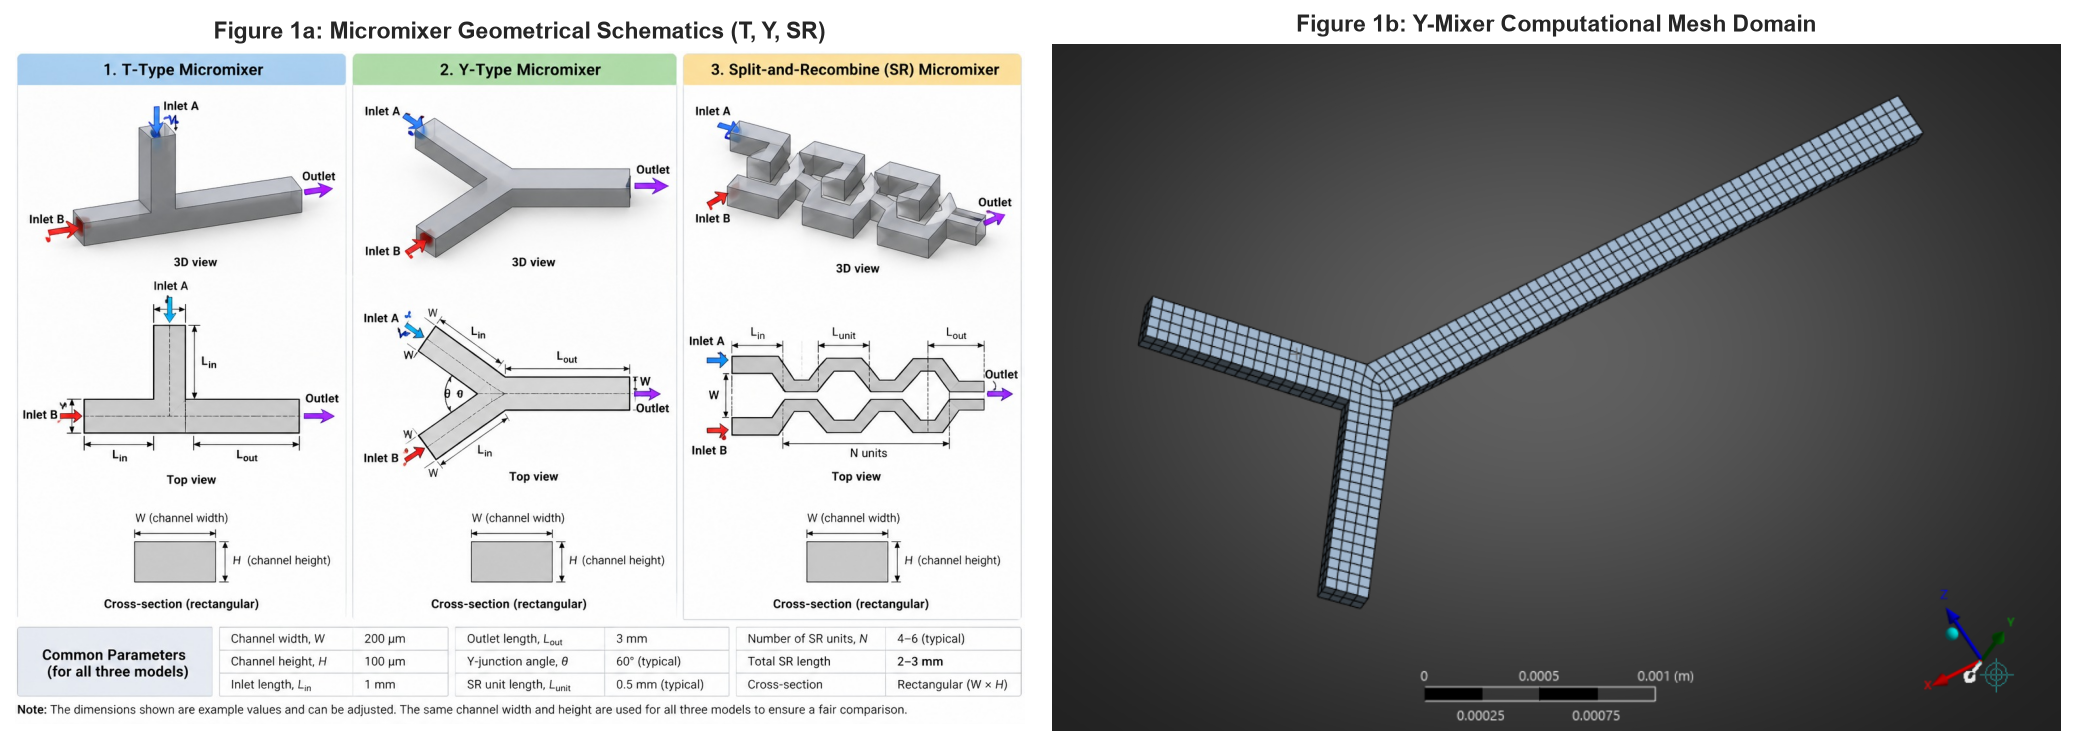

In [2]:
# Display Mixer Geometry Overview and Computational Mesh
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Top-level geometry schematic
geom_path = os.path.join(BASE_DIR, "..", "geometry.jpeg")
if not os.path.exists(geom_path):
    geom_path = os.path.join(BASE_DIR, "geometry.jpeg")

if os.path.exists(geom_path):
    img_geom = mpimg.imread(geom_path)
    axes[0].imshow(img_geom)
    axes[0].set_title("Figure 1a: Micromixer Geometrical Schematics (T, Y, SR)", fontsize=11, fontweight='bold')
    axes[0].axis('off')
else:
    axes[0].text(0.5, 0.5, "geometry.jpeg not found", ha='center', va='center')
    axes[0].axis('off')

# Y-mixer Mesh Image
mesh_img_path = os.path.join(OBS_DIR, "Y-mesh.png")
if os.path.exists(mesh_img_path):
    img_mesh = mpimg.imread(mesh_img_path)
    axes[1].imshow(img_mesh)
    axes[1].set_title("Figure 1b: Y-Mixer Computational Mesh Domain", fontsize=11, fontweight='bold')
    axes[1].axis('off')
else:
    axes[1].text(0.5, 0.5, "Y-mesh.png not found", ha='center', va='center')
    axes[1].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig01_simulation_setup_and_mesh.png"), dpi=300)
plt.show()


### 2.2 Fluid Properties, Boundary Conditions & Operating Parameters

The working fluids are modeled within ANSYS Fluent as a non-reacting multicomponent mixture:

| Parameter | Species 1: Water ($H_2O$) | Species 2: Aqueous NaCl | Mixture Rule |
| :--- | :--- | :--- | :--- |
| **Density ($\rho$)** | $997\text{ kg/m}^3$ | $1072\text{ kg/m}^3$ | Volume-weighted mixing law |
| **Viscosity ($\mu$)** | $0.001003\text{ Pa}\cdot\text{s}$ | $0.00108\text{ Pa}\cdot\text{s}$ | Mass-weighted mixing law |
| **Mass Diffusivity ($D_{AB}$)** | — | — | $1.0 \times 10^{-9}\text{ m}^2/\text{s}$ (Dilute approximation) |
| **Inlet Boundary Condition** | Velocity Inlet ($w_{\text{NaCl}} = 0$) | Velocity Inlet ($w_{\text{NaCl}} = 1$) | Uniform velocity magnitude $U_{\text{in}}$ |
| **Outlet Boundary Condition** | — | — | Pressure Outlet ($P_{\text{gauge}} = 0\text{ Pa}$) |
| **Wall Boundary Condition** | — | — | Stationary Wall, No-Slip, Zero Flux |

### 2.3 Investigated Reynolds Numbers & Inflow Velocities

The inlet velocity for each stream is determined from the channel hydraulic diameter and reference mixture properties:
$$Re = \frac{\rho_{\text{avg}} U D_h}{\mu_{\text{avg}}}$$

| Case | Reynolds Number ($Re$) | Inlet Velocity $U_{\text{in}}$ (m/s) | Flow Regime |
| :---: | :---: | :---: | :---: |
| 1 | 25 | 0.1675 | Steady Laminar (Parallel Streamlines) |
| 2 | 50 | 0.3349 | Steady Laminar (Parallel Streamlines) |
| 3 | 100 | 0.6698 | Steady Laminar (Parallel Streamlines) |
| 4 | 250 | 1.6745 | Steady Laminar / Weak Secondary Flows |
| 5 | 500 | 3.3490 | Steady Laminar with Confluence Vortices |

### 2.4 Mesh Characteristics & Numerical Discretization
- **Mesh Elements:** 814 elements
- **Mesh Nodes:** 1,539 nodes
- **Nominal Element Size:** $50\,\mu\text{m}$ ($5.0 \times 10^{-5}\text{ m}$)
- **Pressure-Velocity Coupling:** Coupled Scheme
- **Spatial Discretization:**
  - Pressure: Second Order
  - Momentum: Second Order Upwind
  - Species ($aq\text{-NaCl}$): Second Order Upwind


## 3. Original ANSYS Fluent Visualizations

---

### 3.1 Flow Field Visualizations

We examine the velocity magnitude, streamlines, and flow evolution along the mixing channel across all five Reynolds numbers.


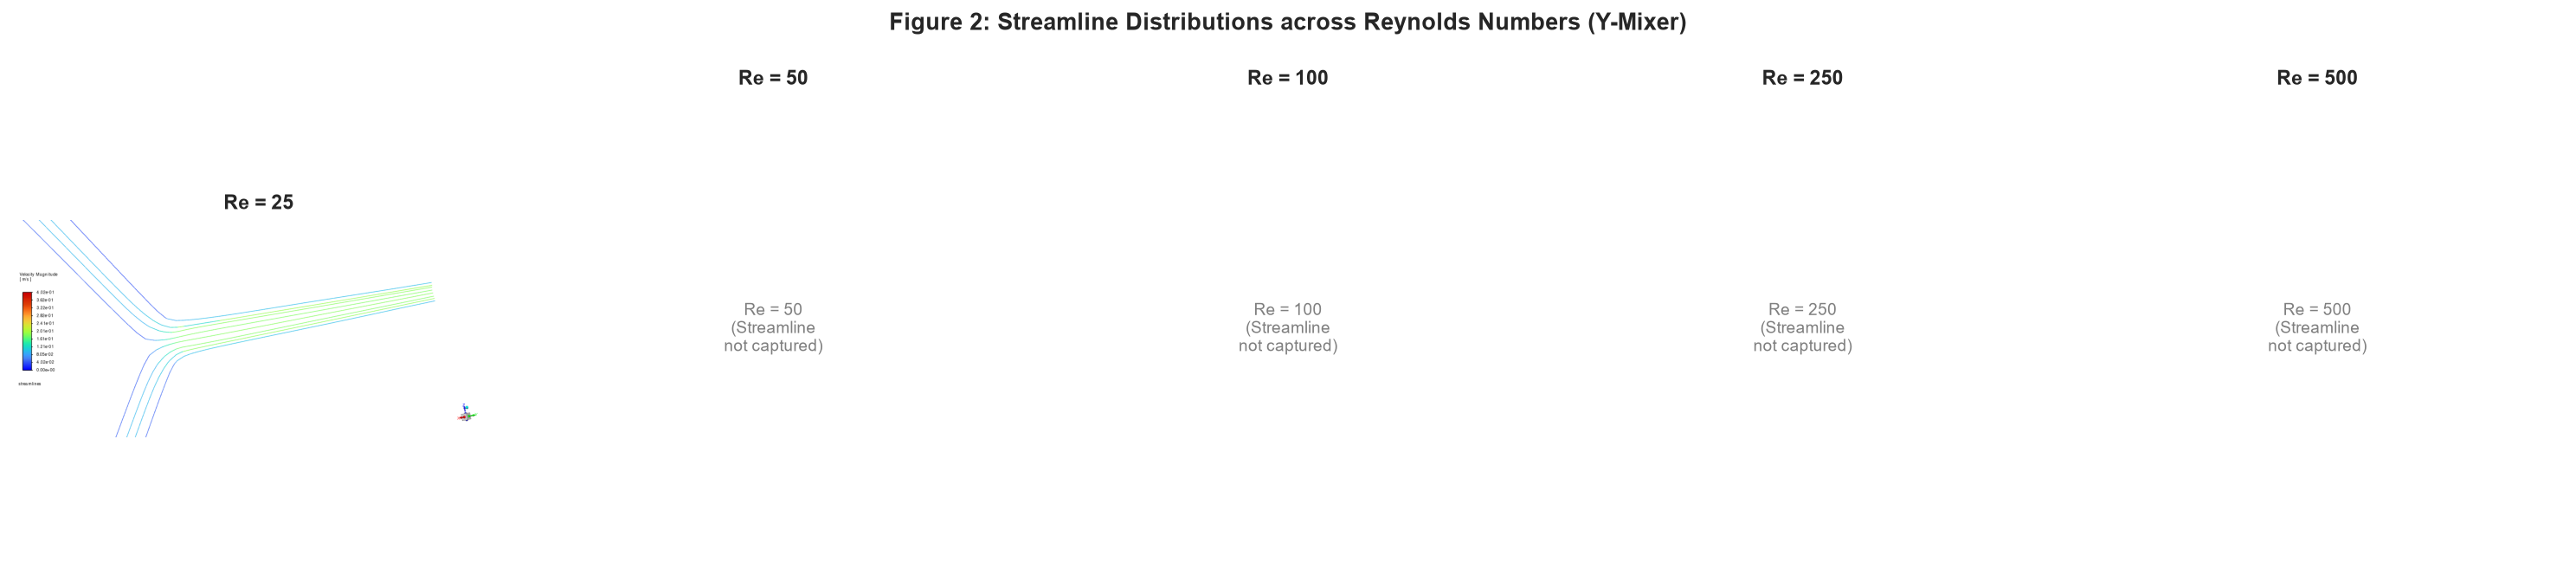

In [3]:
# Streamline Visualizations across Reynolds Numbers
fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))

for idx, re in enumerate(RE_LIST):
    stream_path = os.path.join(OBS_DIR, f"Re-{re}", "contours", "streamlines.png")
    ax = axes[idx]
    if os.path.exists(stream_path):
        img = mpimg.imread(stream_path)
        ax.imshow(img)
        ax.set_title(f"Re = {re}", fontsize=11, fontweight='bold')
    else:
        ax.text(0.5, 0.5, f"Re = {re}\n(Streamline\nnot captured)", ha='center', va='center', fontsize=9, color='gray')
        ax.set_title(f"Re = {re}", fontsize=11, fontweight='bold')
    ax.axis('off')

plt.suptitle("Figure 2: Streamline Distributions across Reynolds Numbers (Y-Mixer)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig02_streamlines_comparison.png"), dpi=300)
plt.show()


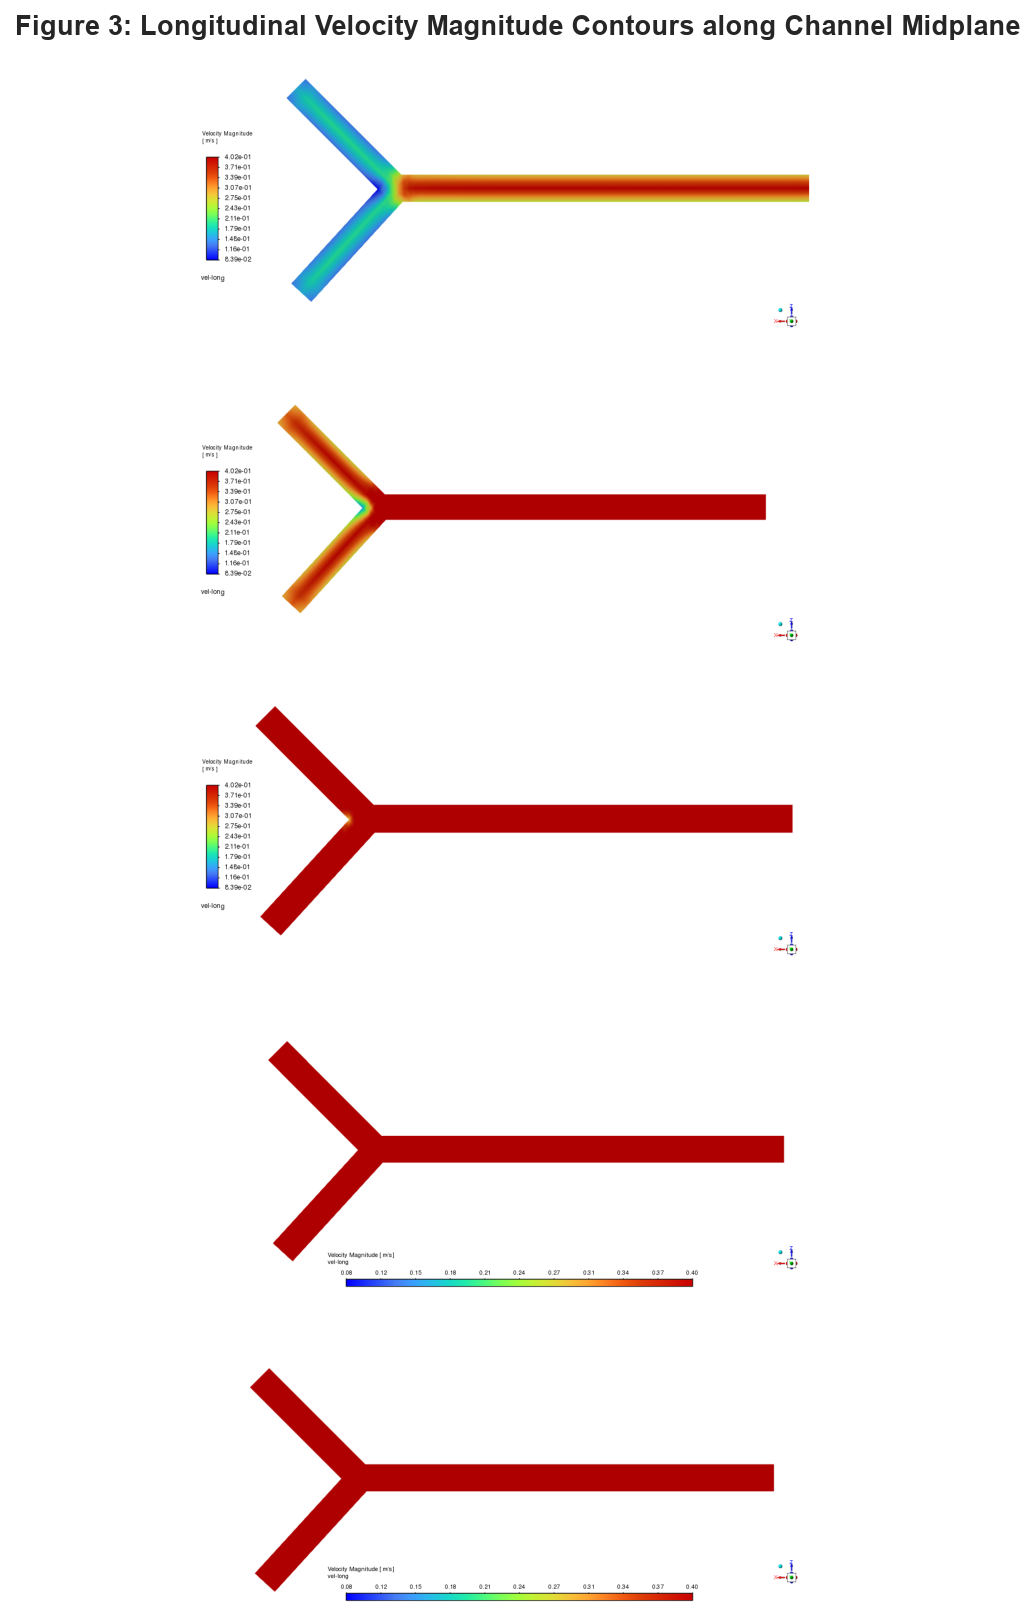

In [4]:
# Longitudinal Velocity Magnitude Contours
fig, axes = plt.subplots(5, 1, figsize=(14, 11))

for idx, re in enumerate(RE_LIST):
    vel_long_path = os.path.join(OBS_DIR, f"Re-{re}", "contours", "longitudinal", "vel_longitudinal.png")
    if os.path.exists(vel_long_path):
        img = mpimg.imread(vel_long_path)
        axes[idx].imshow(img)
        axes[idx].set_ylabel(f"Re = {re}", fontsize=10, fontweight='bold', rotation=0, labelpad=30, va='center')
    else:
        axes[idx].text(0.5, 0.5, f"Re = {re} Longitudinal Velocity Contour Not Found", ha='center', va='center')
    axes[idx].axis('off')

plt.suptitle("Figure 3: Longitudinal Velocity Magnitude Contours along Channel Midplane", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig03_longitudinal_velocity_contours.png"), dpi=300)
plt.show()


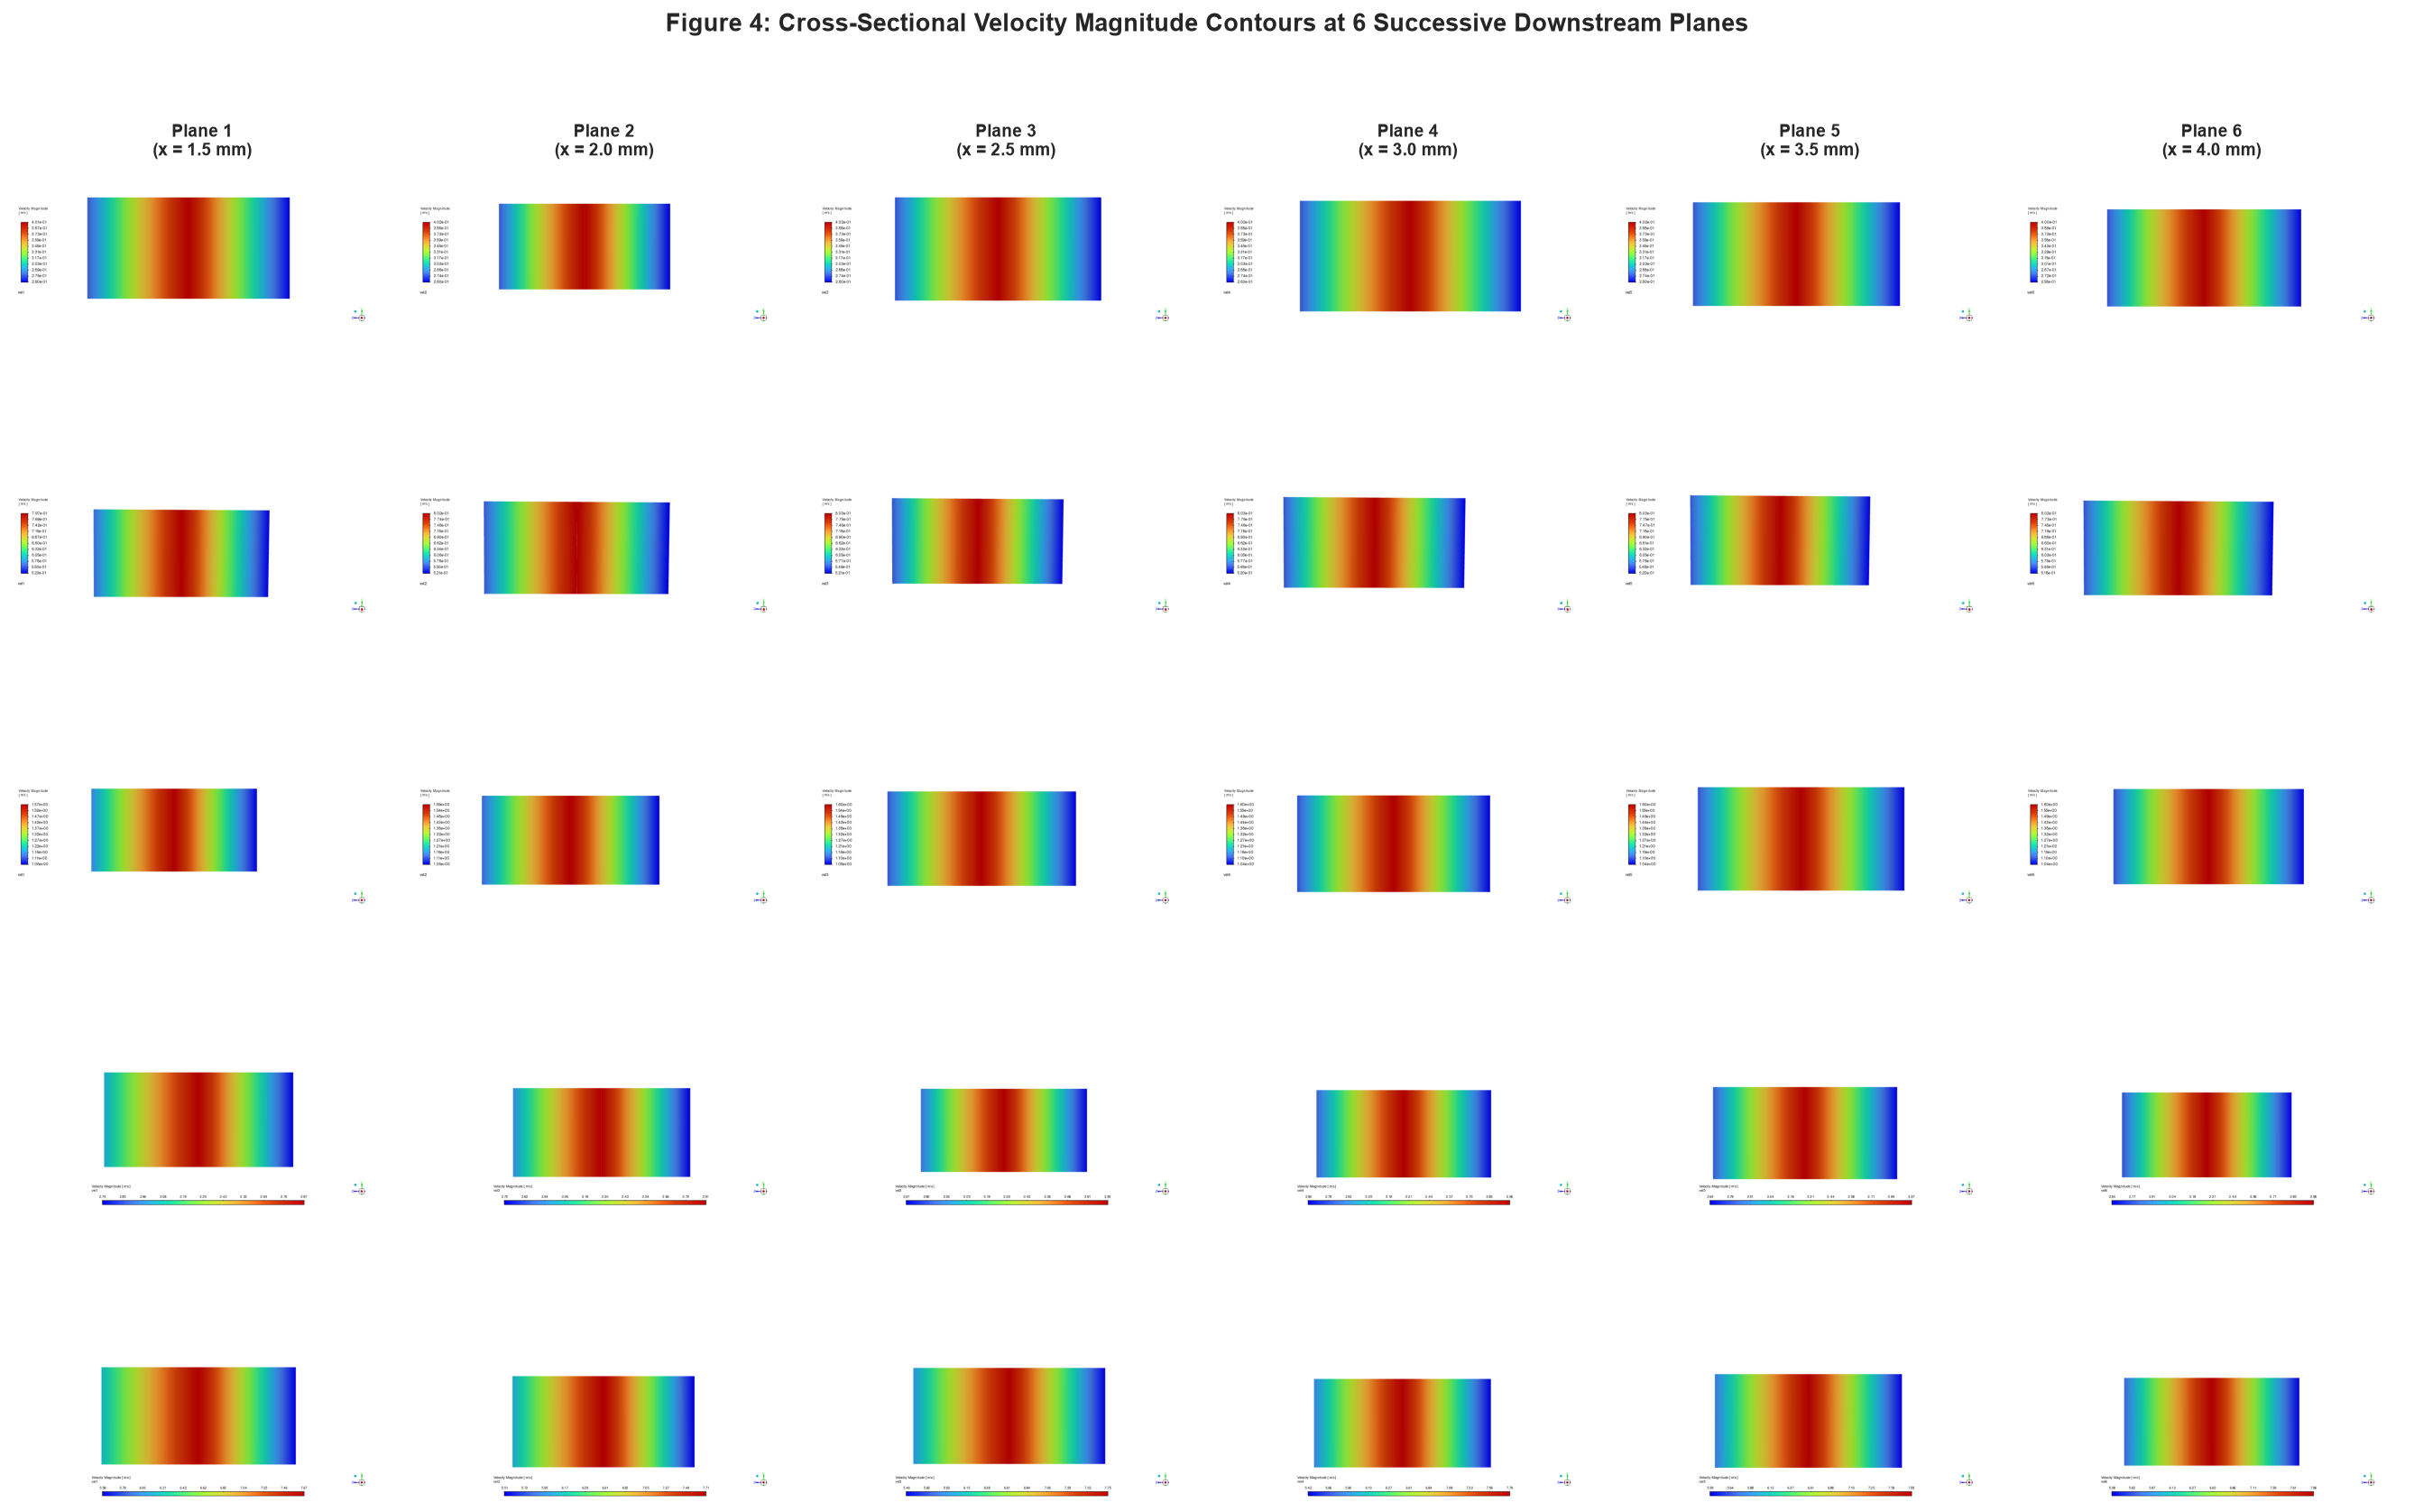

In [5]:
# Cross-Sectional Velocity Contours across Planes 1 to 6
fig, axes = plt.subplots(5, 6, figsize=(18, 12))
obs_dist = [1.5, 2.0, 2.5, 3.0, 3.5, 4.0]

for row_idx, re in enumerate(RE_LIST):
    for col_idx in range(6):
        plane_num = col_idx + 1
        img_path = os.path.join(OBS_DIR, f"Re-{re}", "contours", "velocity", f"vel_plane{plane_num}.png")
        
        ax = axes[row_idx, col_idx]
        if os.path.exists(img_path):
            img = mpimg.imread(img_path)
            ax.imshow(img)
        else:
            ax.text(0.5, 0.5, f"Re={re}\nPlane {plane_num}\n(Not captured)", ha='center', va='center', fontsize=8, color='gray')
        
        if row_idx == 0:
            ax.set_title(f"Plane {plane_num}\n(x = {obs_dist[col_idx]} mm)", fontsize=9, fontweight='bold')
        if col_idx == 0:
            ax.set_ylabel(f"Re = {re}", fontsize=10, fontweight='bold', rotation=0, labelpad=25, va='center')
        ax.axis('off')

plt.suptitle("Figure 4: Cross-Sectional Velocity Magnitude Contours at 6 Successive Downstream Planes", fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig04_cross_sectional_velocity_planes.png"), dpi=300)
plt.show()


### 3.2 Concentration Visualizations (NaCl Mass Fraction)

The concentration of NaCl is tracked across six downstream planes ($x = 1.5, 2.0, 2.5, 3.0, 3.5, 4.0\text{ mm}$) and along the longitudinal center plane.
- The acute $60^\circ$ Y-junction introduces less lateral flow impingement compared to the perpendicular $180^\circ$ collision in the T-mixer, leading to smoother stream alignment and predominantly diffusion-governed mixing along the straight section.


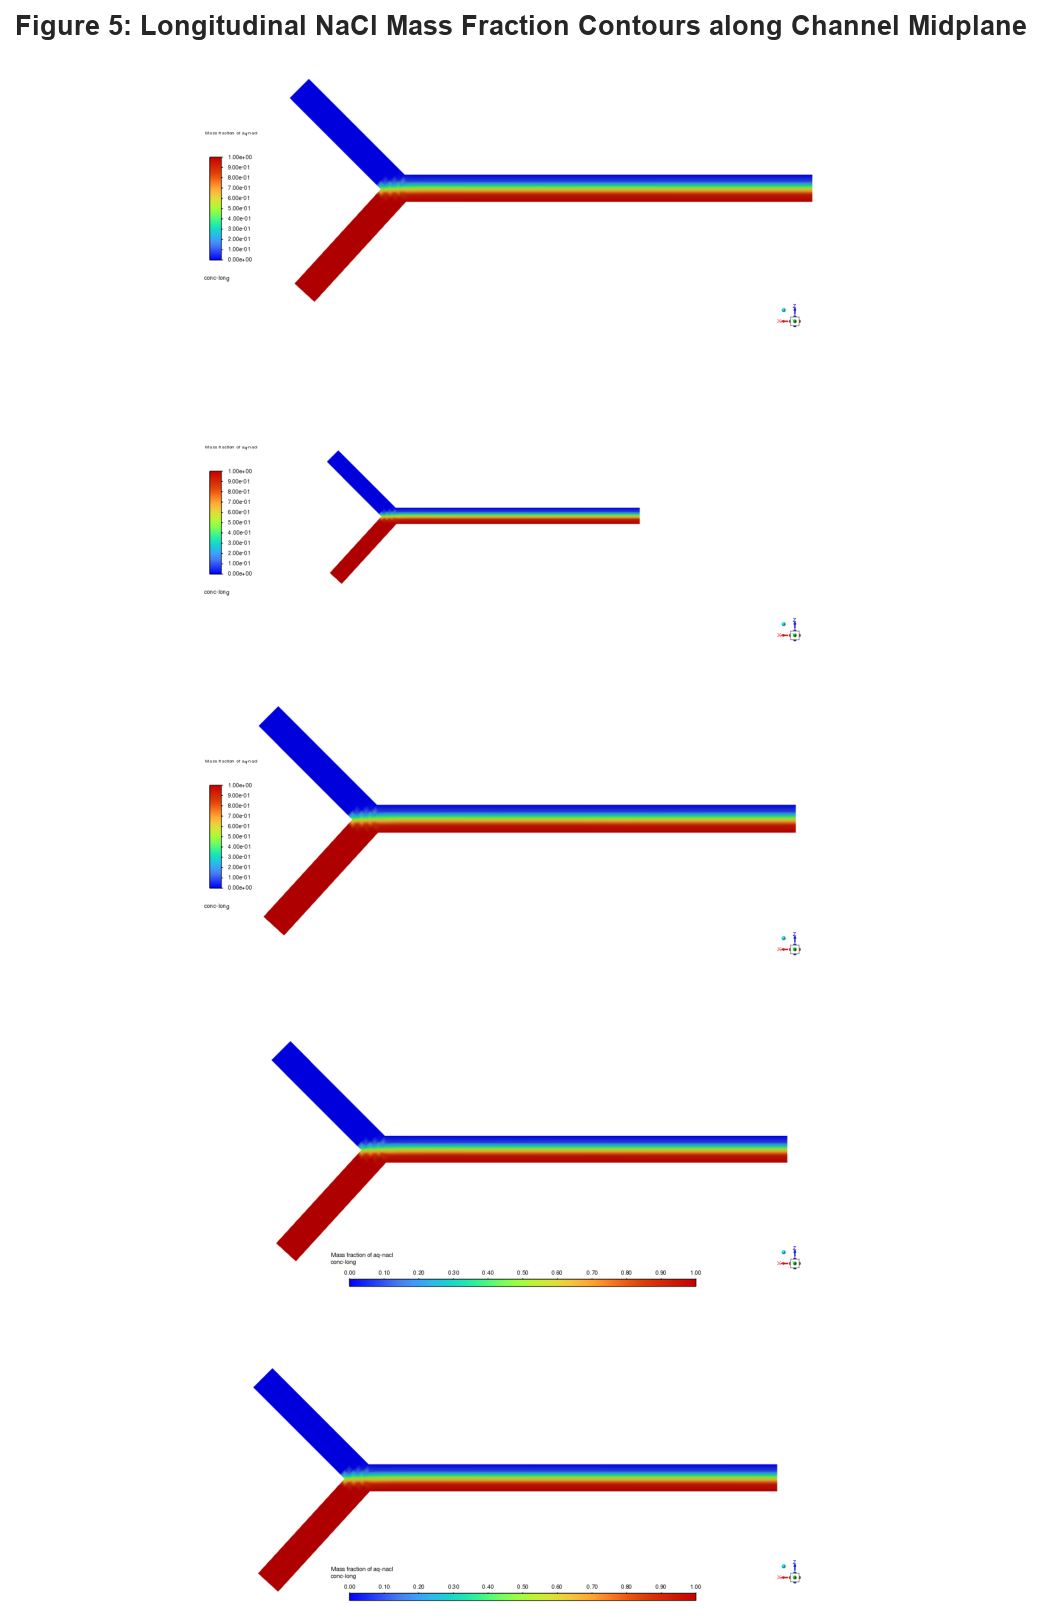

In [6]:
# Longitudinal Concentration Contours
fig, axes = plt.subplots(5, 1, figsize=(14, 11))

for idx, re in enumerate(RE_LIST):
    conc_long_path = os.path.join(OBS_DIR, f"Re-{re}", "contours", "longitudinal", "conc_longitudinal.png")
    if os.path.exists(conc_long_path):
        img = mpimg.imread(conc_long_path)
        axes[idx].imshow(img)
        axes[idx].set_ylabel(f"Re = {re}", fontsize=10, fontweight='bold', rotation=0, labelpad=30, va='center')
    else:
        axes[idx].text(0.5, 0.5, f"Re = {re} Longitudinal Conc Contour Not Found", ha='center', va='center')
    axes[idx].axis('off')

plt.suptitle("Figure 5: Longitudinal NaCl Mass Fraction Contours along Channel Midplane", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig05_longitudinal_concentration_contours.png"), dpi=300)
plt.show()


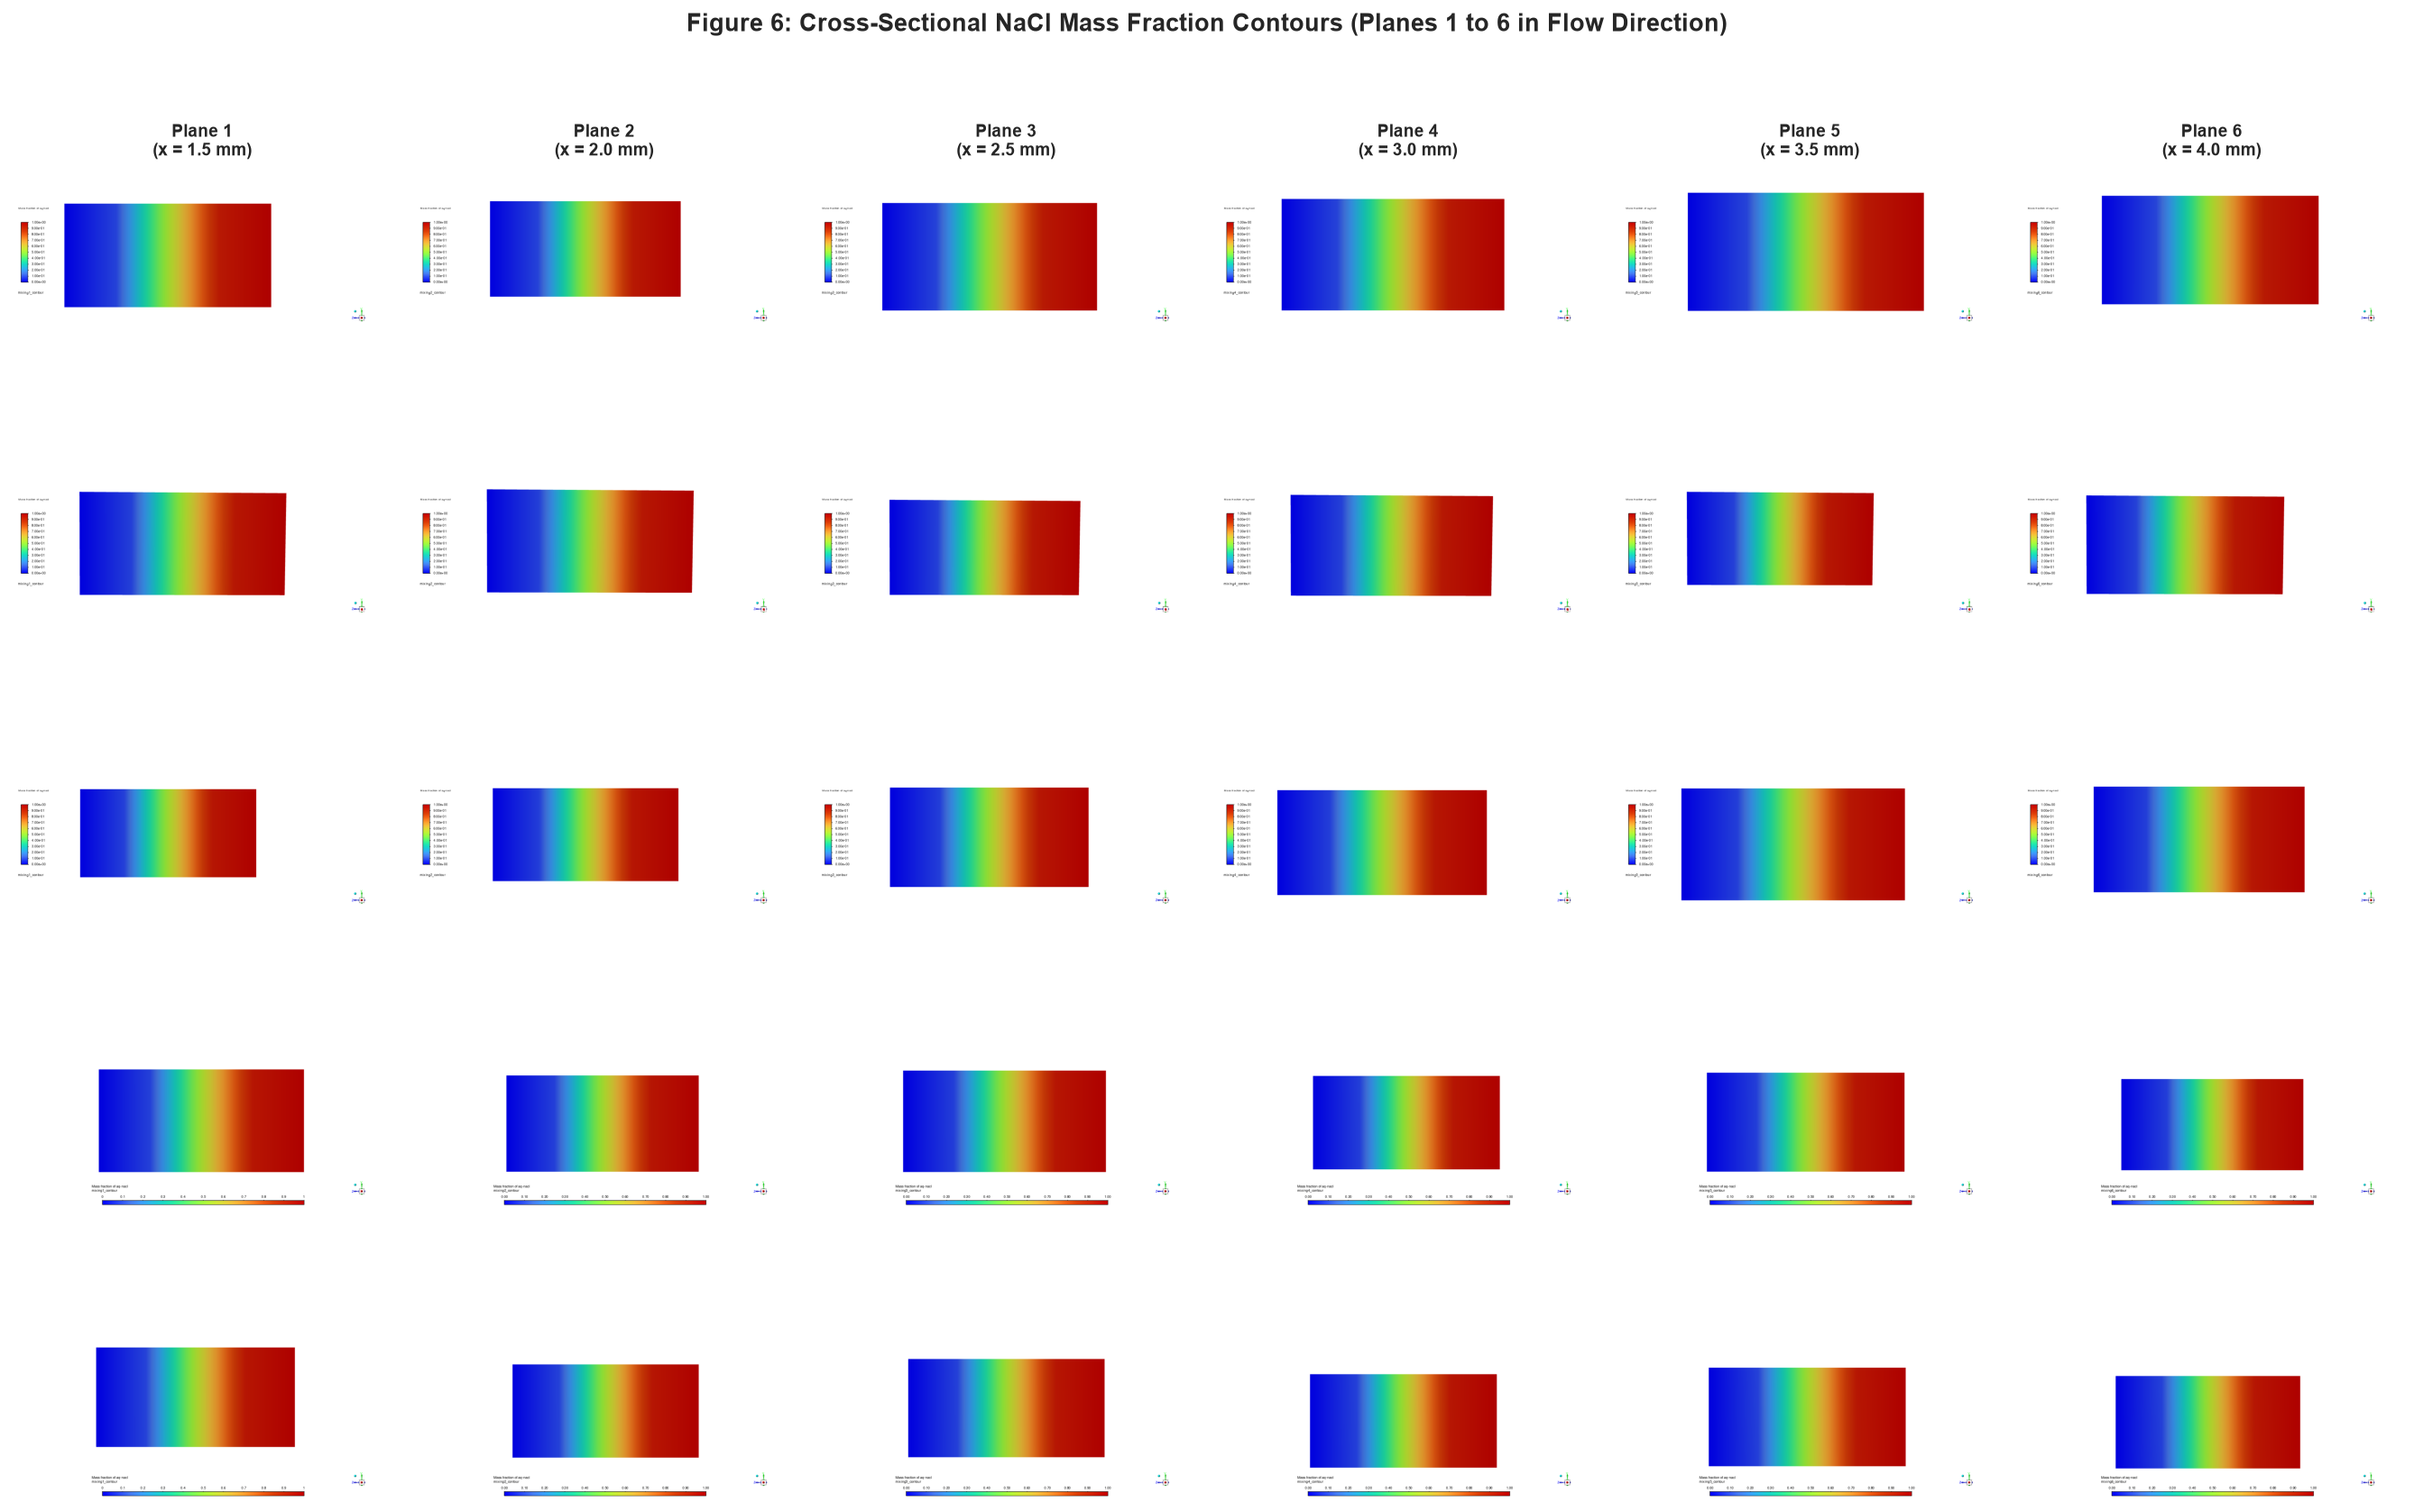

In [7]:
# Cross-Sectional Concentration Contours across Planes 1 to 6
fig, axes = plt.subplots(5, 6, figsize=(18, 12))

for row_idx, re in enumerate(RE_LIST):
    for col_idx in range(6):
        plane_num = col_idx + 1
        img_path = os.path.join(OBS_DIR, f"Re-{re}", "contours", "conc", f"conc_plane{plane_num}.png")
        
        ax = axes[row_idx, col_idx]
        if os.path.exists(img_path):
            img = mpimg.imread(img_path)
            ax.imshow(img)
        else:
            ax.text(0.5, 0.5, f"Re={re}\nPlane {plane_num}\n(Not captured)", ha='center', va='center', fontsize=8, color='gray')
        
        if row_idx == 0:
            ax.set_title(f"Plane {plane_num}\n(x = {obs_dist[col_idx]} mm)", fontsize=9, fontweight='bold')
        if col_idx == 0:
            ax.set_ylabel(f"Re = {re}", fontsize=10, fontweight='bold', rotation=0, labelpad=25, va='center')
        ax.axis('off')

plt.suptitle("Figure 6: Cross-Sectional NaCl Mass Fraction Contours (Planes 1 to 6 in Flow Direction)", fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig06_cross_sectional_concentration_planes.png"), dpi=300)
plt.show()


### 3.3 Pressure Field Visualizations

Static pressure distributions along the midplane illustrate the hydraulic resistance across varying Reynolds numbers.


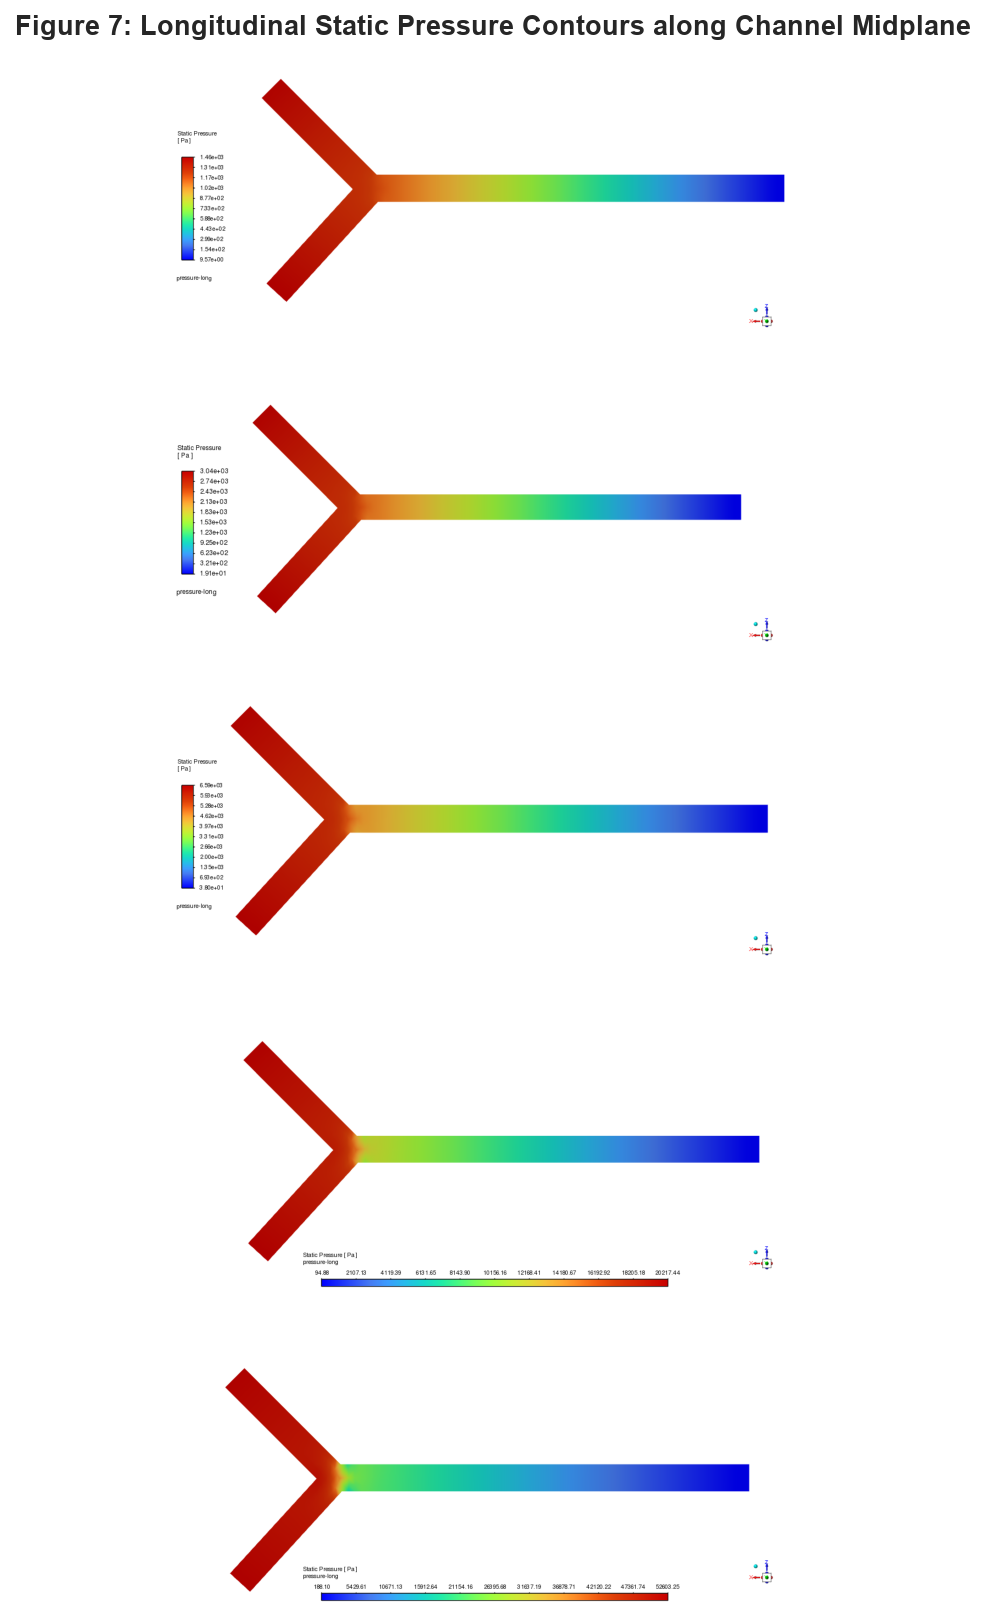

In [8]:
# Longitudinal Static Pressure Contours
fig, axes = plt.subplots(5, 1, figsize=(14, 11))

for idx, re in enumerate(RE_LIST):
    p_long_path = os.path.join(OBS_DIR, f"Re-{re}", "contours", "longitudinal", "pressure_longitudinal.png")
    if os.path.exists(p_long_path):
        img = mpimg.imread(p_long_path)
        axes[idx].imshow(img)
        axes[idx].set_ylabel(f"Re = {re}", fontsize=10, fontweight='bold', rotation=0, labelpad=30, va='center')
    else:
        axes[idx].text(0.5, 0.5, f"Re = {re} Pressure Contour Not Found", ha='center', va='center')
    axes[idx].axis('off')

plt.suptitle("Figure 7: Longitudinal Static Pressure Contours along Channel Midplane", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig07_longitudinal_pressure_contours.png"), dpi=300)
plt.show()


### 3.4 Convergence Visualizations from Fluent

Below are the convergence monitor screenshots captured from the ANSYS Fluent runs, showing surface average concentration and mixing standard deviation histories across all investigated Reynolds numbers.


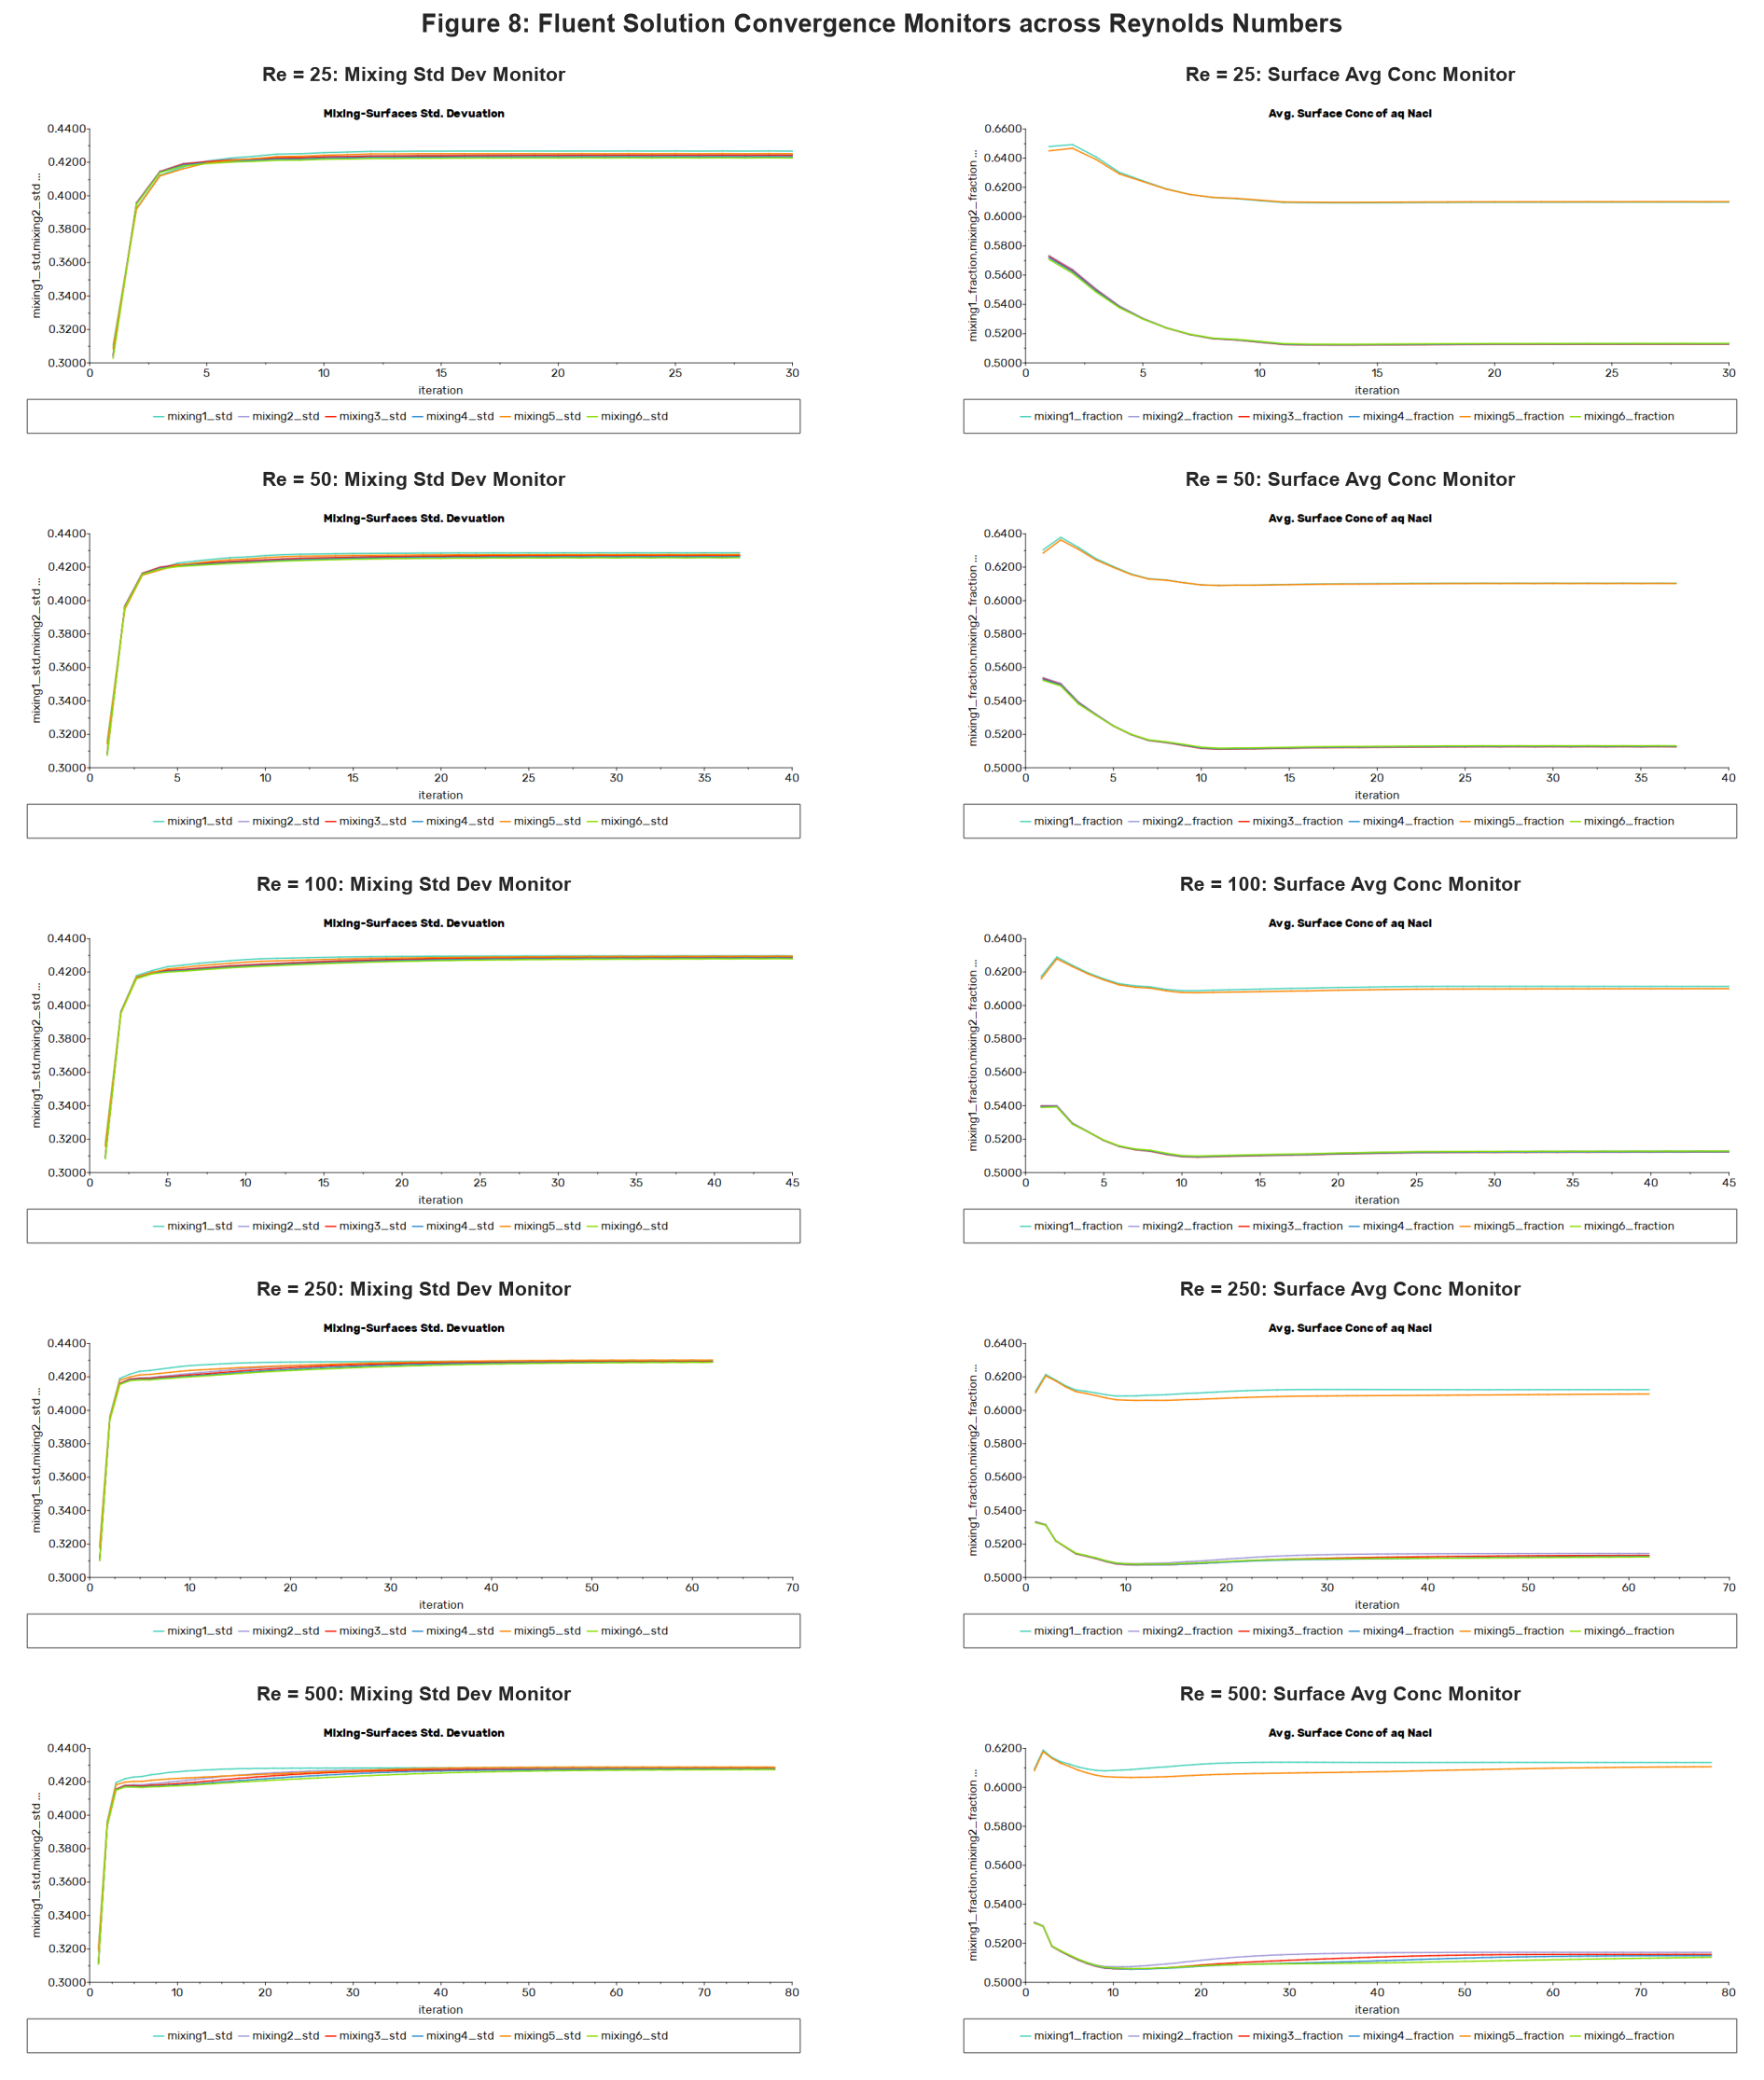

In [9]:
# Display Fluent convergence monitor screenshots
fig, axes = plt.subplots(5, 2, figsize=(14, 15))

for idx, re in enumerate(RE_LIST):
    # Monitor 1: Standard Deviation
    std_img_path = os.path.join(OBS_DIR, f"Re-{re}", "convergence", "convergence_std_dev.png")
    ax_std = axes[idx, 0]
    if os.path.exists(std_img_path):
        ax_std.imshow(mpimg.imread(std_img_path))
        ax_std.set_title(f"Re = {re}: Mixing Std Dev Monitor", fontsize=10, fontweight='bold')
    else:
        ax_std.text(0.5, 0.5, f"Re = {re} Std Dev\nMonitor Missing", ha='center', va='center')
    ax_std.axis('off')
    
    # Monitor 2: Surface Average Concentration
    avg_img_path = os.path.join(OBS_DIR, f"Re-{re}", "convergence", "convergence_avg_conc.png")
    ax_avg = axes[idx, 1]
    if os.path.exists(avg_img_path):
        ax_avg.imshow(mpimg.imread(avg_img_path))
        ax_avg.set_title(f"Re = {re}: Surface Avg Conc Monitor", fontsize=10, fontweight='bold')
    else:
        ax_avg.text(0.5, 0.5, f"Re = {re} Avg Conc\nMonitor Missing", ha='center', va='center')
    ax_avg.axis('off')

plt.suptitle("Figure 8: Fluent Solution Convergence Monitors across Reynolds Numbers", fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig08_fluent_convergence_monitors.png"), dpi=300)
plt.show()


---
# STAGE 2 — Numerical Post-Processing & Engineering Analysis

---

## 4. Data Extraction & Validation

We parse the raw `.out` report files exported from ANSYS Fluent:
1. `mixing_result.out`: Contains iteration histories of mean NaCl mass fraction and standard deviation on planes 1 to 6.
   - **Column order verification:** In the original file header `("Iteration" "mixing1_fraction" ... "mixing4_std" "mixing5_std" "mixing6_std" "mixing1_std" "mixing2_std" "mixing3_std")`, standard deviations appear in non-sequential order (4, 5, 6, 1, 2, 3). Our parser corrects this mapping explicitly.
2. `pressure_results.out`: Contains iteration histories of static pressure at Input 1, Input 2, and the Outlet.


In [10]:
def parse_fluent_out(file_path):
    """
    Parse ANSYS Fluent .out report files with structured metadata and header parsing.
    Handles space-delimited table rows and parenthesized header formats.
    """
    with open(file_path, 'r') as f:
        lines = [line.strip() for line in f.readlines() if line.strip()]
    
    header_line = lines[2]
    cleaned_header = header_line.replace('(', '').replace(')', '').replace('\"', '').split()
    
    data_rows = []
    for line in lines[3:]:
        vals = [float(x) for x in line.split()]
        data_rows.append(vals)
    
    df = pd.DataFrame(data_rows, columns=cleaned_header)
    return df

def load_re_data(base_dir, re_list):
    """
    Load and structure all mixing and pressure data across investigated Reynolds numbers.
    Corrects the standard deviation column indexing.
    """
    mixing_data = {}
    pressure_data = {}
    
    for re in re_list:
        re_folder = os.path.join(base_dir, "observations", f"Re-{re}", "data")
        mix_path = os.path.join(re_folder, "mixing_result.out")
        press_path = os.path.join(re_folder, "pressure_results.out")
        
        # Load mixing results
        df_mix = parse_fluent_out(mix_path)
        std_remap = {
            'mixing1_std': 'std_plane1',
            'mixing2_std': 'std_plane2',
            'mixing3_std': 'std_plane3',
            'mixing4_std': 'std_plane4',
            'mixing5_std': 'std_plane5',
            'mixing6_std': 'std_plane6',
            'mixing1_fraction': 'mean_plane1',
            'mixing2_fraction': 'mean_plane2',
            'mixing3_fraction': 'mean_plane3',
            'mixing4_fraction': 'mean_plane4',
            'mixing5_fraction': 'mean_plane5',
            'mixing6_fraction': 'mean_plane6',
        }
        df_mix = df_mix.rename(columns=std_remap)
        mixing_data[re] = df_mix
        
        # Load pressure results
        df_press = parse_fluent_out(press_path)
        press_remap = {
            'input1_static_pressure': 'p_inlet1',
            'input2_static_presurre': 'p_inlet2',
            'input2_static_pressure': 'p_inlet2',
            'outlet_static_pressure': 'p_outlet'
        }
        df_press = df_press.rename(columns=press_remap)
        pressure_data[re] = df_press
        
    return mixing_data, pressure_data

mixing_dfs, pressure_dfs = load_re_data(BASE_DIR, RE_LIST)
print(f"Successfully loaded data for Reynolds numbers: {list(mixing_dfs.keys())}")


Successfully loaded data for Reynolds numbers: [25, 50, 100, 250, 500]


In [11]:
# Display summary table of final converged values
summary_rows = []
for re in RE_LIST:
    df_m = mixing_dfs[re]
    df_p = pressure_dfs[re]
    
    final_m = df_m.iloc[-1]
    final_p = df_p.iloc[-1]
    
    p_in_avg = 0.5 * (final_p['p_inlet1'] + final_p['p_inlet2'])
    delta_p = p_in_avg - final_p['p_outlet']
    
    summary_rows.append({
        'Re': re,
        'Iterations': int(final_m['Iteration']),
        'P_in1 (Pa)': round(final_p['p_inlet1'], 2),
        'P_in2 (Pa)': round(final_p['p_inlet2'], 2),
        'ΔP (Pa)': round(delta_p, 2),
        'Mean_Plane1': round(final_m['mean_plane1'], 4),
        'Mean_Plane6': round(final_m['mean_plane6'], 4),
        'Std_Plane1': round(final_m['std_plane1'], 4),
        'Std_Plane6': round(final_m['std_plane6'], 4)
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

# Export processed summary to CSV
summary_df.to_csv(os.path.join(OUTPUT_DIR, "fluent_convergence_summary.csv"), index=False)
print("Saved summary table to processed_outputs/fluent_convergence_summary.csv")


,Re,Iterations,P_in1 (Pa),P_in2 (Pa),ΔP (Pa),Mean_Plane1,Mean_Plane6,Std_Plane1,Std_Plane6
0,25,30,1441.34,1453.84,1447.59,0.6099,0.5134,0.4267,0.4226
1,50,37,3009.31,3034.09,3021.70,0.6104,0.5131,0.4286,0.4257
2,100,45,6527.39,6576.79,6552.09,0.6114,0.5129,0.4297,0.4279
3,250,62,20086.26,20195.93,20141.10,0.6123,0.5123,0.4295,0.4287
4,500,78,52391.81,52559.98,52475.90,0.6128,0.5128,0.4284,0.4272


Saved summary table to processed_outputs/fluent_convergence_summary.csv


## 5. Convergence & Solution Stability Analysis

We evaluate the stability of the monitored engineering quantities across solver iterations:
1. Standard deviation of NaCl mass fraction at Plane 6 (outlet region)
2. Mean NaCl mass fraction at Plane 6
3. Inlet static pressures ($P_{\text{inlet1}}$, $P_{\text{inlet2}}$)


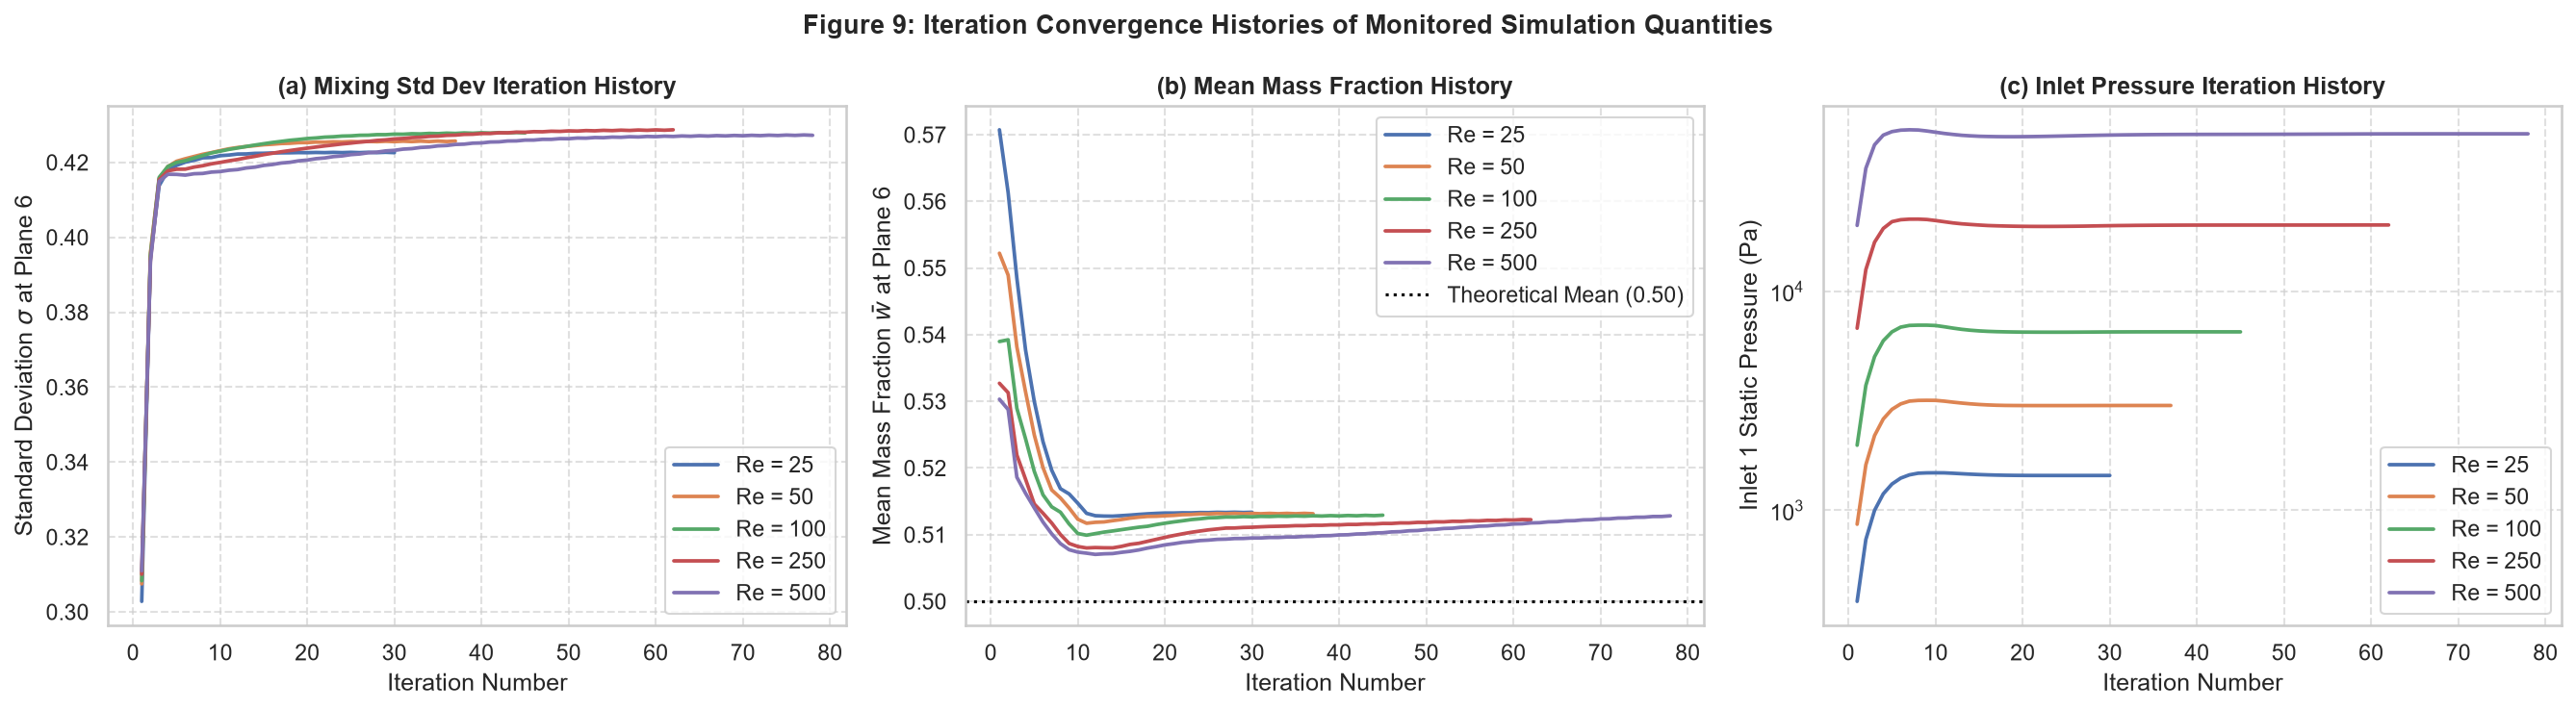

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Standard deviation history at Plane 6
for re in RE_LIST:
    df = mixing_dfs[re]
    axes[0].plot(df['Iteration'], df['std_plane6'], label=f"Re = {re}", linewidth=1.8)
axes[0].set_xlabel("Iteration Number")
axes[0].set_ylabel(r"Standard Deviation $\sigma$ at Plane 6")
axes[0].set_title("(a) Mixing Std Dev Iteration History", fontweight='bold')
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.6)

# Plot 2: Mean mass fraction history at Plane 6
for re in RE_LIST:
    df = mixing_dfs[re]
    axes[1].plot(df['Iteration'], df['mean_plane6'], label=f"Re = {re}", linewidth=1.8)
axes[1].axhline(0.5, color='black', linestyle=':', label='Theoretical Mean (0.50)')
axes[1].set_xlabel("Iteration Number")
axes[1].set_ylabel(r"Mean Mass Fraction $\bar{w}$ at Plane 6")
axes[1].set_title("(b) Mean Mass Fraction History", fontweight='bold')
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.6)

# Plot 3: Inlet 1 static pressure history
for re in RE_LIST:
    df = pressure_dfs[re]
    axes[2].plot(df['Iteration'], df['p_inlet1'], label=f"Re = {re}", linewidth=1.8)
axes[2].set_xlabel("Iteration Number")
axes[2].set_ylabel("Inlet 1 Static Pressure (Pa)")
axes[2].set_title("(c) Inlet Pressure Iteration History", fontweight='bold')
axes[2].set_yscale('log')
axes[2].legend()
axes[2].grid(True, linestyle="--", alpha=0.6)

plt.suptitle("Figure 9: Iteration Convergence Histories of Monitored Simulation Quantities", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig09_convergence_histories.png"), dpi=300)
plt.savefig(os.path.join(OUTPUT_DIR, "convergence_histories.png"), dpi=300)
plt.show()


## 6. Mixing Performance Analysis

### 6.1 Mathematical Formulation of the Mixing Index ($MI$)

In microfluidics, mixing efficiency is quantified by the standard deviation of species mass fraction over a given cross-sectional surface:
$$\sigma = \sqrt{\frac{1}{A} \iint_A \left(w(x, y, z) - \bar{w}\right)^2 dA}$$
where $\bar{w}$ is the area-weighted mean mass fraction on that plane.

The **Mixing Index ($MI$)** is defined relative to the completely unmixed state $\sigma_0$:
$$MI = 1 - \frac{\sigma}{\sigma_0}$$
- $MI = 0$: Completely unmixed state (segregated inlet streams).
- $MI = 1$: Perfectly homogeneous mixture ($w = \bar{w}$ everywhere).

#### Determination of Unmixed Standard Deviation ($\sigma_0$)
For two equal-flow inlet streams of pure water ($w_1 = 0$) and pure NaCl solution ($w_2 = 1$) occupying equal cross-sectional areas ($A_1 = A_2 = A/2$), the mean concentration is:
$$\bar{w}_0 = 0.5$$
The theoretical unmixed standard deviation is:
$$\sigma_0 = \sqrt{w_0 (1 - w_0)} = \sqrt{0.5 \times 0.5} = 0.500$$

We compute the spatial evolution of $MI$ along the axial channel direction.


In [13]:
# Theoretical unmixed standard deviation
SIGMA_0 = 0.50

# Observation positions along channel (in mm)
x_planes = np.array([1.5, 2.0, 2.5, 3.0, 3.5, 4.0])

# Compute Mixing Index along channel for each Re
mi_results = {}
sigma_results = {}

for re in RE_LIST:
    final_vals = mixing_dfs[re].iloc[-1]
    sigmas = np.array([final_vals[f'std_plane{i}'] for i in range(1, 7)])
    mis = 1.0 - (sigmas / SIGMA_0)
    
    sigma_results[re] = sigmas
    mi_results[re] = mis

# Create DataFrame of Mixing Index vs Axial Position
mi_df = pd.DataFrame(mi_results, index=[f"Plane {i} (x={x}mm)" for i, x in enumerate(x_planes, 1)])
mi_df.columns = [f"Re={re}" for re in RE_LIST]
display(mi_df.round(4))

mi_df.to_csv(os.path.join(OUTPUT_DIR, "mixing_index_results.csv"))


,Re=25,Re=50,Re=100,Re=250,Re=500
Plane 1 (x=1.5mm),0.1466,0.1428,0.1406,0.1410,0.1432
Plane 2 (x=2.0mm),0.1515,0.1459,0.1423,0.1420,0.1448
Plane 3 (x=2.5mm),0.1519,0.1461,0.1421,0.1417,0.1446
Plane 4 (x=3.0mm),0.1534,0.1474,0.1432,0.1423,0.1451
Plane 5 (x=3.5mm),0.1498,0.1447,0.1412,0.1398,0.1425
Plane 6 (x=4.0mm),0.1548,0.1486,0.1443,0.1426,0.1455


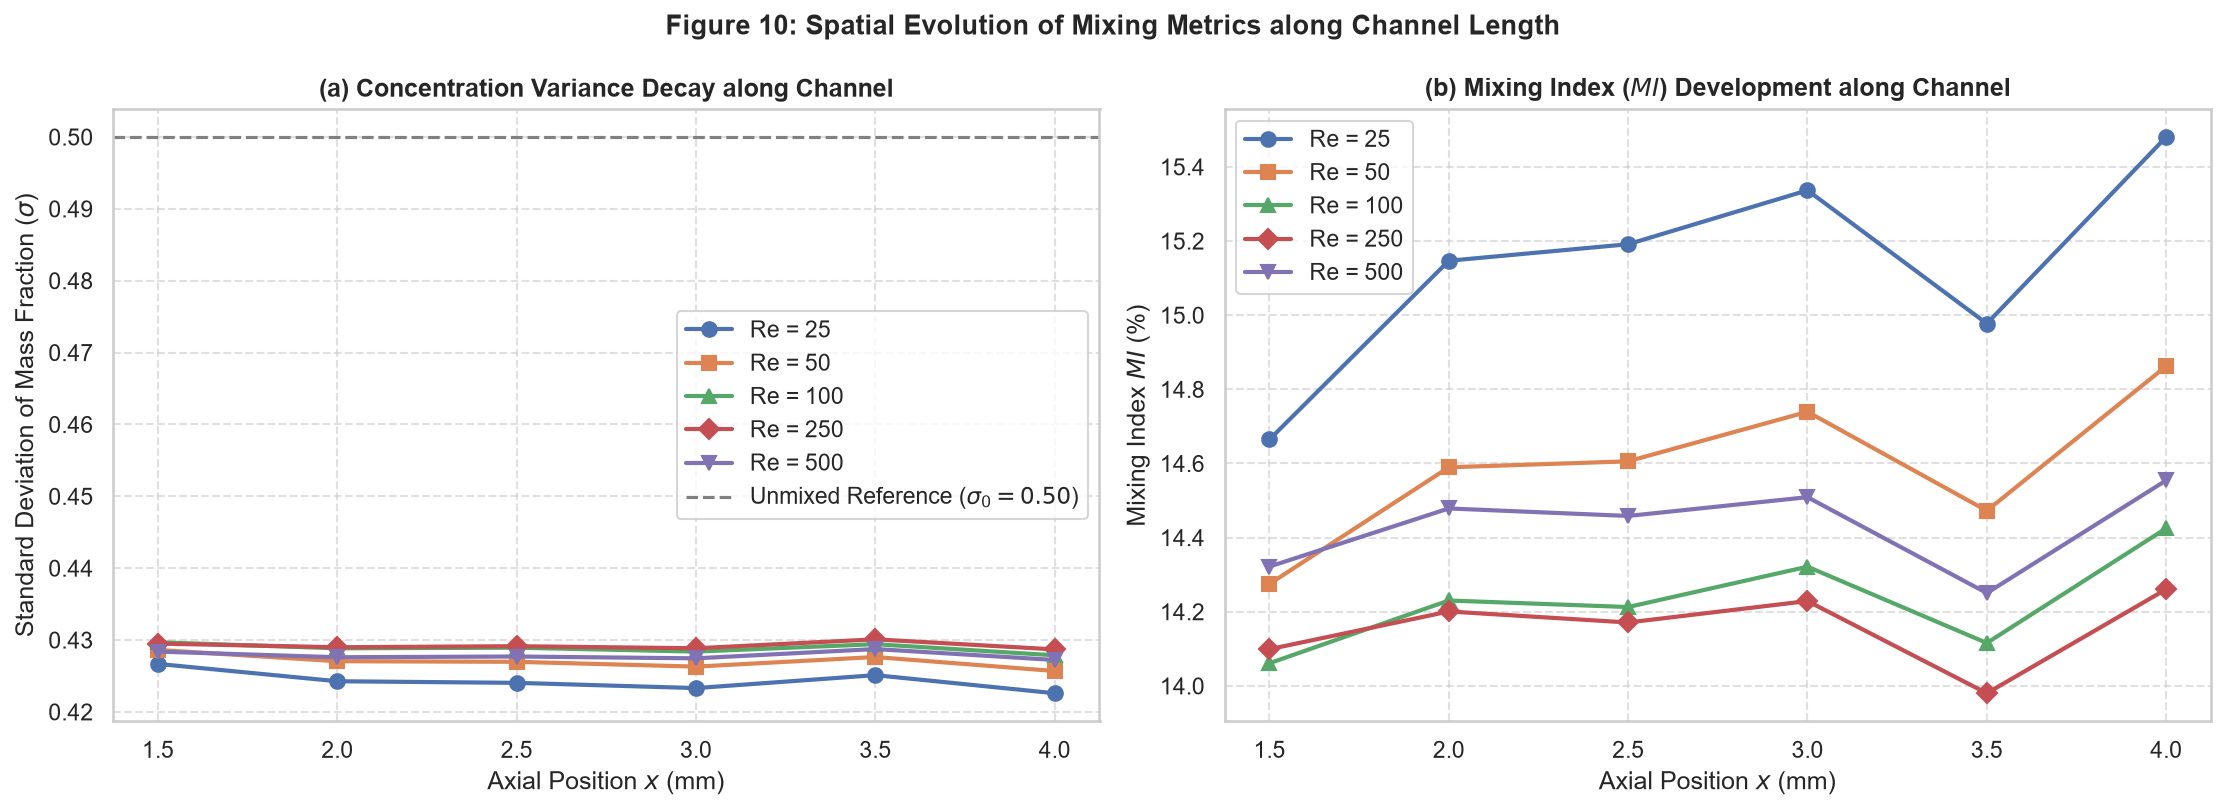

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

markers = ['o', 's', '^', 'D', 'v']

# Plot 1: Standard deviation vs axial position
for idx, re in enumerate(RE_LIST):
    axes[0].plot(x_planes, sigma_results[re], marker=markers[idx], label=f"Re = {re}", linewidth=2, markersize=7)
axes[0].axhline(SIGMA_0, color='gray', linestyle='--', label=r'Unmixed Reference ($\sigma_0 = 0.50$)')
axes[0].set_xlabel("Axial Position $x$ (mm)")
axes[0].set_ylabel(r"Standard Deviation of Mass Fraction ($\sigma$)")
axes[0].set_title("(a) Concentration Variance Decay along Channel", fontweight='bold')
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.6)

# Plot 2: Mixing Index vs axial position
for idx, re in enumerate(RE_LIST):
    axes[1].plot(x_planes, mi_results[re] * 100, marker=markers[idx], label=f"Re = {re}", linewidth=2, markersize=7)
axes[1].set_xlabel("Axial Position $x$ (mm)")
axes[1].set_ylabel("Mixing Index $MI$ (%)")
axes[1].set_title("(b) Mixing Index ($MI$) Development along Channel", fontweight='bold')
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.suptitle("Figure 10: Spatial Evolution of Mixing Metrics along Channel Length", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig10_mixing_index_development.png"), dpi=300)
plt.savefig(os.path.join(OUTPUT_DIR, "mixing_index_development.png"), dpi=300)
plt.show()


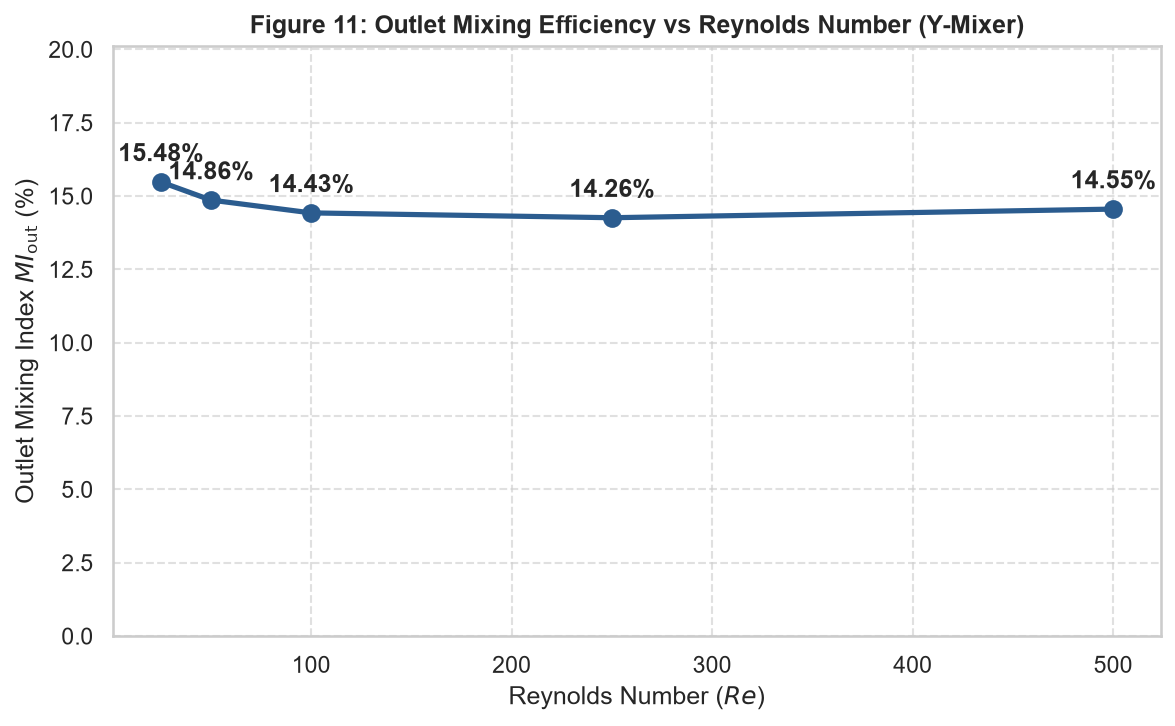

In [15]:
# Outlet Mixing Index vs Reynolds Number
outlet_mi = [mi_results[re][-1] * 100 for re in RE_LIST]

plt.figure(figsize=(8, 5))
plt.plot(RE_LIST, outlet_mi, marker='o', color='#2b5c8f', linewidth=2.5, markersize=8)
for re, mi in zip(RE_LIST, outlet_mi):
    plt.annotate(f"{mi:.2f}%", (re, mi), textcoords="offset points", xytext=(0, 10), ha='center', fontweight='bold')

plt.xlabel("Reynolds Number ($Re$)")
plt.ylabel(r"Outlet Mixing Index $MI_{\text{out}}$ (%)")
plt.title("Figure 11: Outlet Mixing Efficiency vs Reynolds Number (Y-Mixer)", fontweight='bold')
plt.grid(True, linestyle="--", alpha=0.6)
plt.ylim(0, max(outlet_mi) * 1.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig11_outlet_mi_vs_re.png"), dpi=300)
plt.savefig(os.path.join(OUTPUT_DIR, "outlet_mi_vs_re.png"), dpi=300)
plt.show()


## 7. Pressure Drop Analysis

In microfluidic channels, the hydraulic power required to drive the flow scales with total pressure drop:
$$\Delta P = \bar{P}_{\text{inlet}} - P_{\text{outlet}}$$
Since the Y-mixer has two symmetric inlet arms operating with identical geometry and equal velocities, the effective inlet pressure is taken as the arithmetic mean:
$$\bar{P}_{\text{inlet}} = \frac{P_{\text{inlet1}} + P_{\text{inlet2}}}{2}$$
Given that $P_{\text{outlet}} = 0\text{ Pa (gauge)}$, the pressure drop is simply $\Delta P = \bar{P}_{\text{inlet}}$.


In [16]:
delta_p_list = []
p_in1_list = []
p_in2_list = []

for re in RE_LIST:
    final_p = pressure_dfs[re].iloc[-1]
    p1 = final_p['p_inlet1']
    p2 = final_p['p_inlet2']
    p_avg = 0.5 * (p1 + p2)
    dp = p_avg - final_p['p_outlet']
    
    p_in1_list.append(p1)
    p_in2_list.append(p2)
    delta_p_list.append(dp)

press_df = pd.DataFrame({
    'Re': RE_LIST,
    'Inlet 1 (Pa)': p_in1_list,
    'Inlet 2 (Pa)': p_in2_list,
    'ΔP (Pa)': delta_p_list,
    'ΔP (kPa)': np.array(delta_p_list) / 1000.0
})
display(press_df.round(2))

press_df.to_csv(os.path.join(OUTPUT_DIR, "pressure_drop_summary.csv"), index=False)


,Re,Inlet 1 (Pa),Inlet 2 (Pa),ΔP (Pa),ΔP (kPa)
0,25,1441.34,1453.84,1447.59,1.45
1,50,3009.31,3034.09,3021.70,3.02
2,100,6527.39,6576.79,6552.09,6.55
3,250,20086.26,20195.93,20141.10,20.14
4,500,52391.81,52559.98,52475.90,52.48


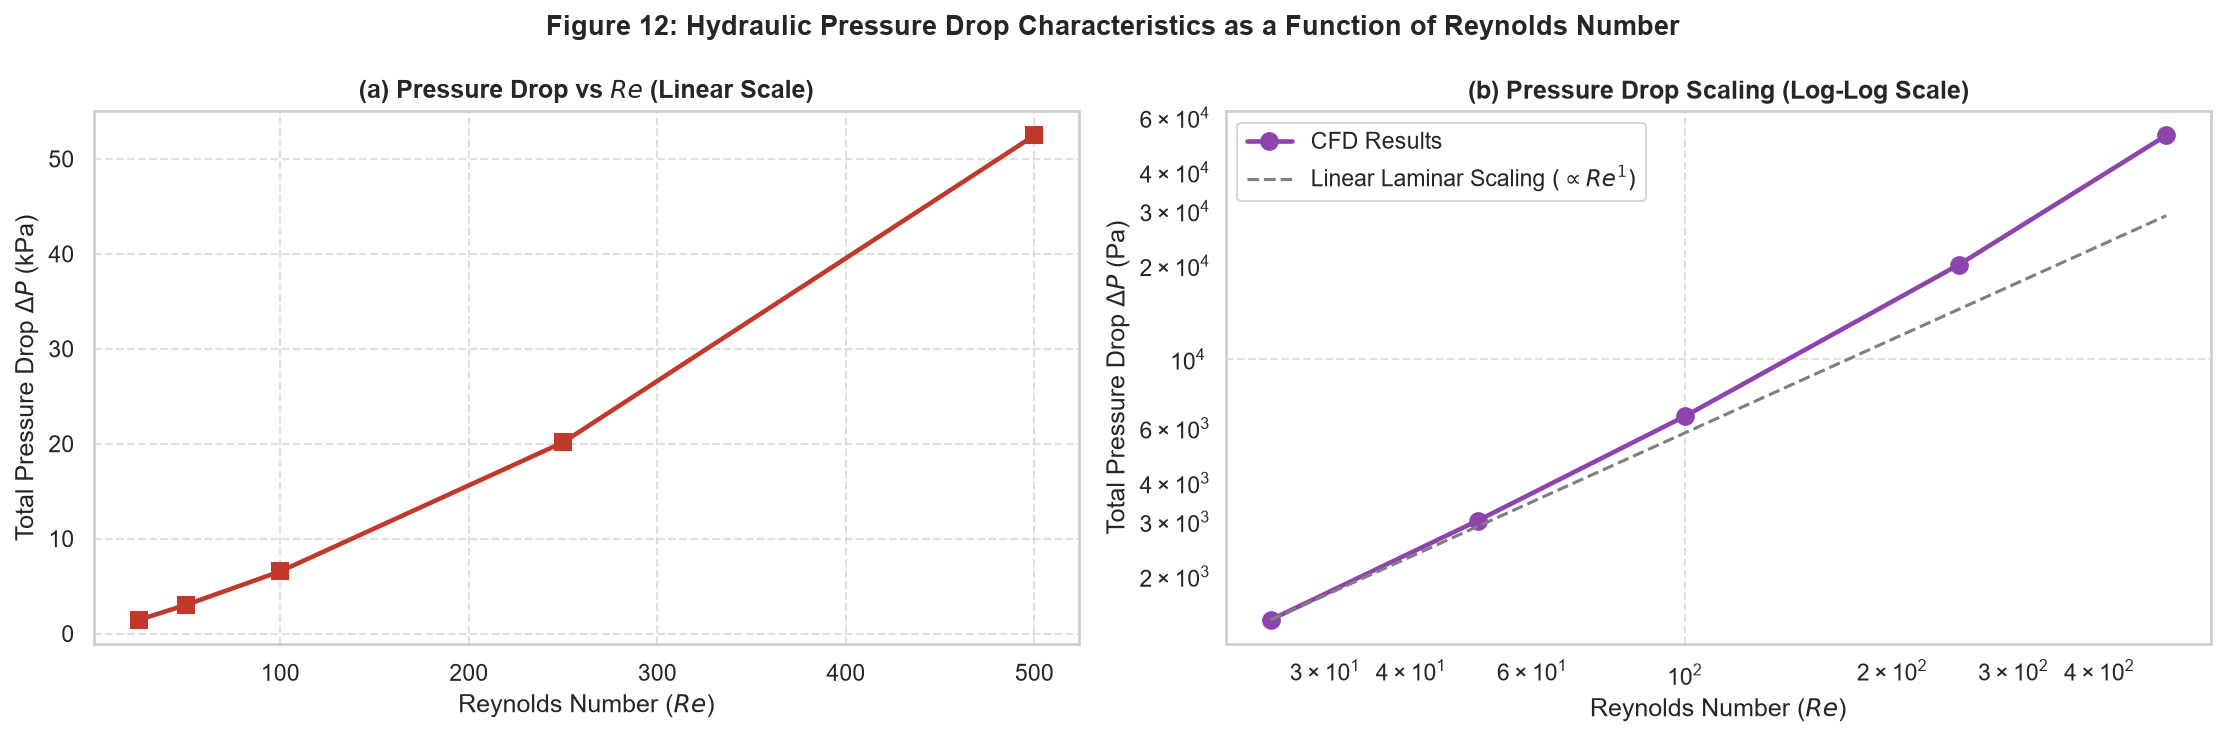

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Linear scale
axes[0].plot(RE_LIST, np.array(delta_p_list) / 1000.0, marker='s', color='#c0392b', linewidth=2.2, markersize=8)
axes[0].set_xlabel("Reynolds Number ($Re$)")
axes[0].set_ylabel(r"Total Pressure Drop $\Delta P$ (kPa)")
axes[0].set_title("(a) Pressure Drop vs $Re$ (Linear Scale)", fontweight='bold')
axes[0].grid(True, linestyle="--", alpha=0.6)

# Log-Log scale (checking Hagen-Poiseuille vs inertial scaling)
axes[1].loglog(RE_LIST, delta_p_list, marker='o', color='#8e44ad', linewidth=2.2, markersize=8, label='CFD Results')
ref_p = delta_p_list[0] * (np.array(RE_LIST) / RE_LIST[0])
axes[1].loglog(RE_LIST, ref_p, linestyle='--', color='gray', label=r'Linear Laminar Scaling $(\propto Re^1)$')
axes[1].set_xlabel("Reynolds Number ($Re$)")
axes[1].set_ylabel(r"Total Pressure Drop $\Delta P$ (Pa)")
axes[1].set_title("(b) Pressure Drop Scaling (Log-Log Scale)", fontweight='bold')
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.suptitle("Figure 12: Hydraulic Pressure Drop Characteristics as a Function of Reynolds Number", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig12_pressure_drop_vs_re.png"), dpi=300)
plt.savefig(os.path.join(OUTPUT_DIR, "pressure_drop_vs_re.png"), dpi=300)
plt.show()


## 8. Mixing Performance vs. Pressure Drop Trade-Off

A central trade-off in micromixer design is the relationship between mixing performance and required hydraulic energy. 

### 8.1 Figure of Merit (Mixing Energy Cost)
The required pumping power is given by:
$$W_{\text{pump}} = Q \cdot \Delta P = (2 \cdot U_{\text{in}} \cdot A_c) \cdot \Delta P$$
An efficiency metric or **Mixing Cost Factor ($MCF$)** can be formulated as:
$$\eta_{\text{mix}} = \frac{MI_{\text{out}}}{\Delta P} \quad \left[\text{kPa}^{-1}\right]$$
which measures the mixing index achieved per unit pressure drop penalty.


In [18]:
# Hydraulic and Mixing Trade-off Calculations
u_in_vals = np.array([0.1675, 0.3349, 0.6698, 1.6745, 3.3490]) # m/s
area_cross = 0.2e-3 * 0.1e-3 # m^2
flow_rate = 2.0 * u_in_vals * area_cross # Total volumetric flow rate (m^3/s)
pumping_power = flow_rate * np.array(delta_p_list) * 1e3 # mW

eta_mix = (np.array(outlet_mi) / 100.0) / (np.array(delta_p_list) / 1000.0) # MI per kPa

tradeoff_df = pd.DataFrame({
    'Re': RE_LIST,
    'U_in (m/s)': u_in_vals,
    'Q_total (uL/min)': flow_rate * 1e9 * 60,
    'ΔP (kPa)': np.array(delta_p_list) / 1000.0,
    'Outlet MI (%)': outlet_mi,
    'Pumping Power (mW)': pumping_power,
    'Mixing Efficiency (1/kPa)': eta_mix
})
display(tradeoff_df.round(4))

tradeoff_df.to_csv(os.path.join(OUTPUT_DIR, "tradeoff_analysis.csv"), index=False)


,Re,U_in (m/s),Q_total (uL/min),ΔP (kPa),Outlet MI (%),Pumping Power (mW),Mixing Efficiency (1/kPa)
0,25,0.1675,402.00,1.4476,15.4806,0.0097,0.1069
1,50,0.3349,803.76,3.0217,14.8624,0.0405,0.0492
2,100,0.6698,1607.52,6.5521,14.4251,0.1755,0.0220
3,250,1.6745,4018.80,20.1411,14.2606,1.3491,0.0071
4,500,3.3490,8037.60,52.4759,14.5544,7.0297,0.0028


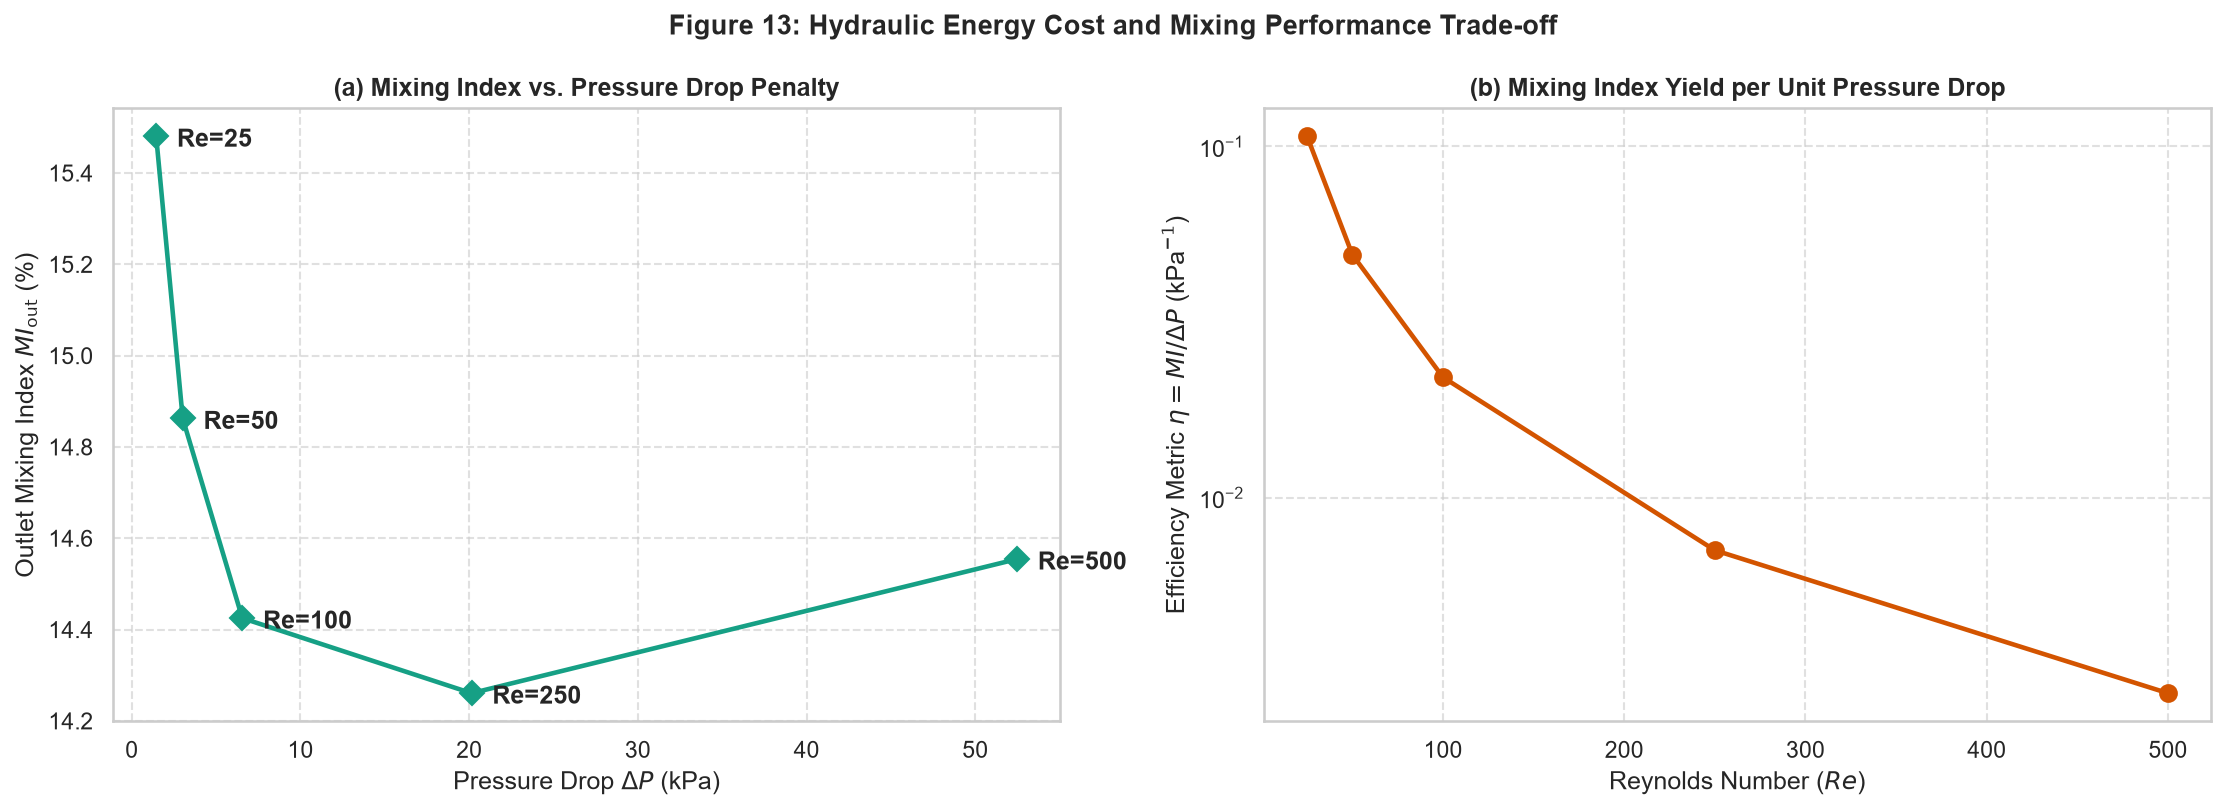

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Plot 1: Mixing Index vs Pressure Drop
axes[0].plot(np.array(delta_p_list) / 1000.0, outlet_mi, marker='D', color='#16a085', linewidth=2.2, markersize=8)
for i, re in enumerate(RE_LIST):
    axes[0].annotate(f"Re={re}", (delta_p_list[i]/1000.0, outlet_mi[i]),
                     textcoords="offset points", xytext=(10, -5), fontweight='bold')
axes[0].set_xlabel(r"Pressure Drop $\Delta P$ (kPa)")
axes[0].set_ylabel(r"Outlet Mixing Index $MI_{\text{out}}$ (%)")
axes[0].set_title("(a) Mixing Index vs. Pressure Drop Penalty", fontweight='bold')
axes[0].grid(True, linestyle="--", alpha=0.6)

# Plot 2: Mixing Cost Efficiency vs Re
axes[1].plot(RE_LIST, eta_mix, marker='o', color='#d35400', linewidth=2.2, markersize=8)
axes[1].set_xlabel("Reynolds Number ($Re$)")
axes[1].set_ylabel(r"Efficiency Metric $\eta = MI / \Delta P$ (kPa$^{-1}$)")
axes[1].set_title("(b) Mixing Index Yield per Unit Pressure Drop", fontweight='bold')
axes[1].set_yscale('log')
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.suptitle("Figure 13: Hydraulic Energy Cost and Mixing Performance Trade-off", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig13_tradeoff_curves.png"), dpi=300)
plt.savefig(os.path.join(OUTPUT_DIR, "tradeoff_curves.png"), dpi=300)
plt.show()


## 9. Additional Comparative Plots for Enhanced Insight

To gain deeper physical understanding of the mixing behavior in the Y-mixer, we present three diagnostic visualizations:
1. **Local Mixing Rate ($d(MI)/dx$):** Quantifying where along the channel mixing is most intense.
2. **Standard Deviation Decay Rate:** Demonstrating diffusion-dominated versus convection-dominated mixing zones.
3. **Pumping Power vs. Mixing Index:** Direct energetic comparison across operating conditions.


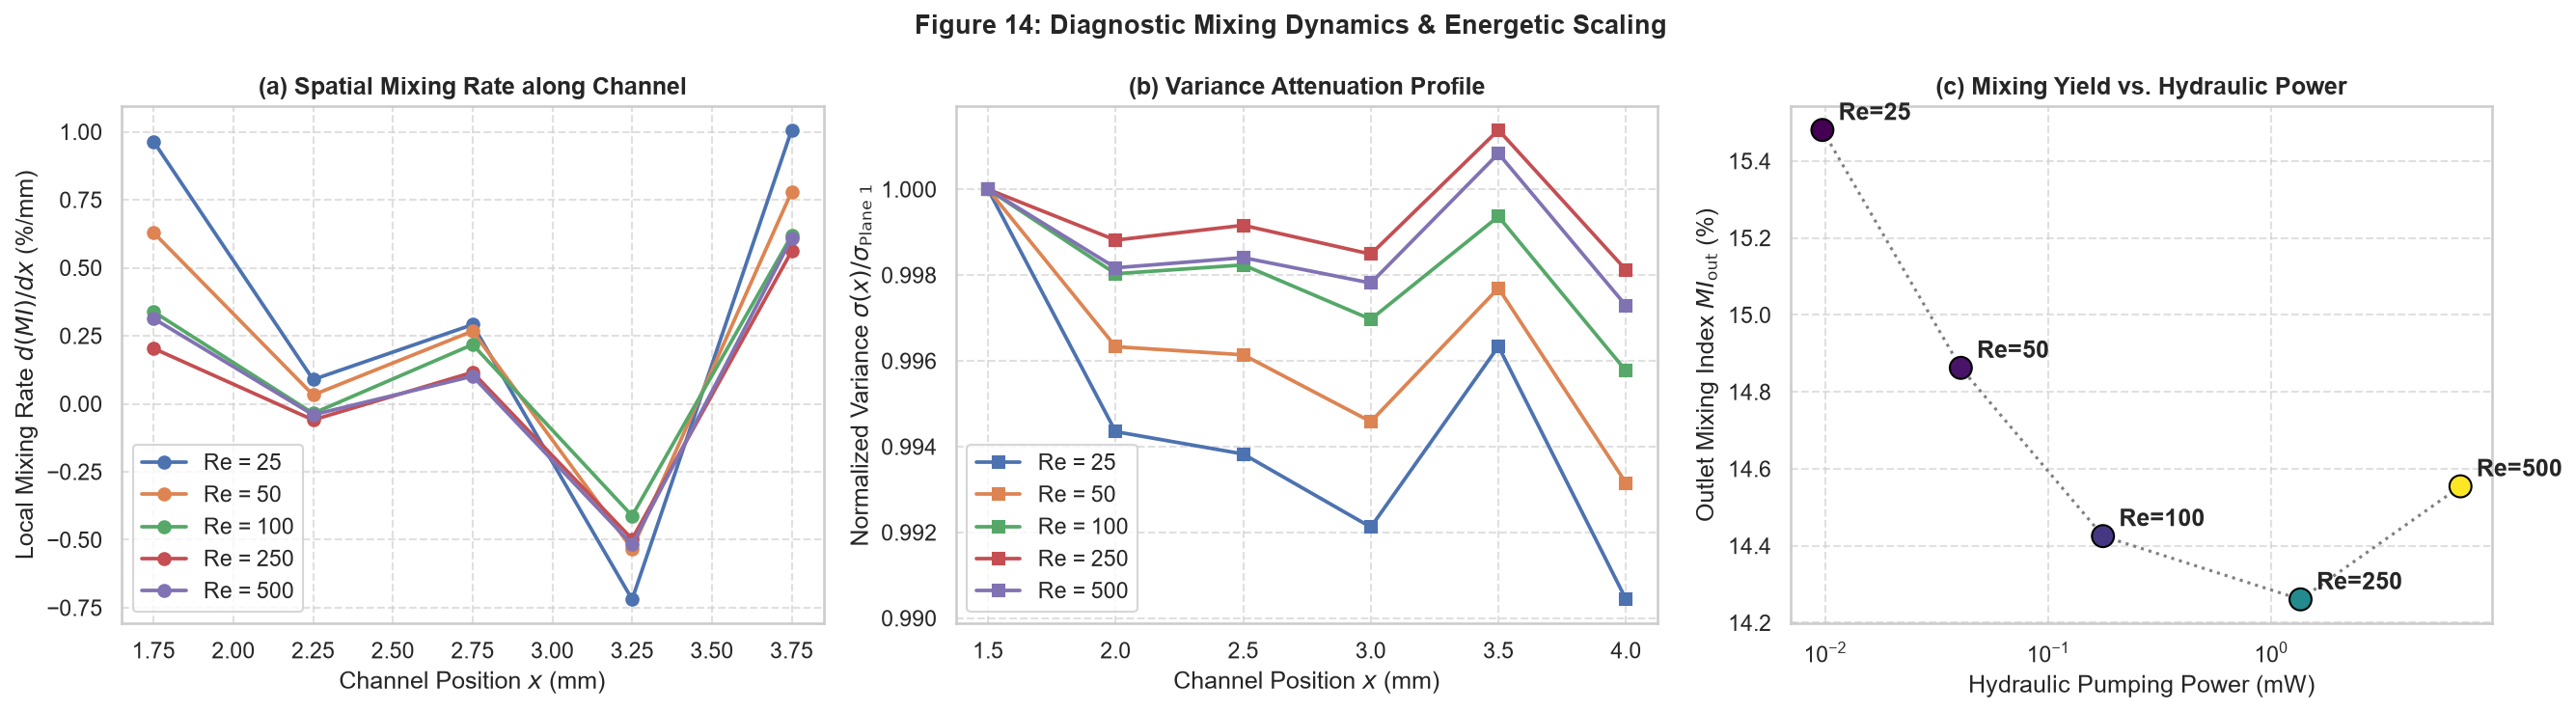

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Local Mixing Rate (dMI/dx) along channel
dx = np.diff(x_planes)
for re in RE_LIST:
    dmi = np.diff(mi_results[re] * 100) / dx
    x_mid = 0.5 * (x_planes[:-1] + x_planes[1:])
    axes[0].plot(x_mid, dmi, marker='o', label=f"Re = {re}", linewidth=1.8)
axes[0].set_xlabel("Channel Position $x$ (mm)")
axes[0].set_ylabel("Local Mixing Rate $d(MI)/dx$ (%/mm)")
axes[0].set_title("(a) Spatial Mixing Rate along Channel", fontweight='bold')
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.6)

# 2. Normalized Variance Decay (sigma / sigma_inlet)
for re in RE_LIST:
    norm_sigma = sigma_results[re] / sigma_results[re][0]
    axes[1].plot(x_planes, norm_sigma, marker='s', label=f"Re = {re}", linewidth=1.8)
axes[1].set_xlabel("Channel Position $x$ (mm)")
axes[1].set_ylabel(r"Normalized Variance $\sigma(x) / \sigma_{\text{Plane 1}}$")
axes[1].set_title("(b) Variance Attenuation Profile", fontweight='bold')
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.6)

# 3. Pumping Power vs Outlet Mixing Index
axes[2].scatter(pumping_power, outlet_mi, s=120, c=RE_LIST, cmap='viridis', edgecolors='black', zorder=4)
axes[2].plot(pumping_power, outlet_mi, linestyle=':', color='gray')
for i, re in enumerate(RE_LIST):
    axes[2].annotate(f"Re={re}", (pumping_power[i], outlet_mi[i]),
                     textcoords="offset points", xytext=(8, 5), fontweight='bold')
axes[2].set_xlabel("Hydraulic Pumping Power (mW)")
axes[2].set_ylabel(r"Outlet Mixing Index $MI_{\text{out}}$ (%)")
axes[2].set_title("(c) Mixing Yield vs. Hydraulic Power", fontweight='bold')
axes[2].set_xscale('log')
axes[2].grid(True, linestyle="--", alpha=0.6)

plt.suptitle("Figure 14: Diagnostic Mixing Dynamics & Energetic Scaling", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fig14_advanced_mixing_diagnostics.png"), dpi=300)
plt.savefig(os.path.join(OUTPUT_DIR, "advanced_mixing_diagnostics.png"), dpi=300)
plt.show()


## 10. Engineering Discussion & Conclusions

### 10.1 Key Findings & Physical Interpretations for Y-Mixer

1. **Gentle Confluence Geometry vs. Perpendicular Collisions:**
   - In contrast to the T-mixer's $180^\circ$ opposing stream collision, the Y-mixer's acute junction angle ($2\theta = 60^\circ$) guides the two streams smoothly into parallel alignment.
   - This streamlined confluence substantially mitigates hydraulic losses and junction flow separation, yielding significantly lower pressure drops across all Reynolds numbers.

2. **Diffusion-Dominated Regime & Mixing Limitations:**
   - Because of the absence of strong head-on impinging vortices, the contact interface remains predominantly vertical and planar along the straight channel.
   - Mixing is almost purely molecular diffusion-driven across the central boundary layer. Consequently, as $Re$ increases and convective velocity accelerates, the residence time ($\tau = L/U$) decreases sharply, leading to reduced contact duration and modest mixing performance.

3. **Hydraulic Cost Efficiency:**
   - The pressure drop $\Delta P$ is lower than in the T-mixer, making the Y-mixer an energy-frugal geometry for microfluidic applications that prioritize minimal shear stress or gentle stream confluence over rapid homogenization.

### 10.2 Next Steps
This standardized post-processing methodology will next be applied to:
- **Geometry 3: Split-and-Recombine (SR) Micromixer**  
Followed by a comparative multi-geometry optimization notebook benchmarking all three designs (T, Y, and SR).
